<a href="https://colab.research.google.com/github/saatour/GW170817/blob/main/20261013_EAGLE_simulation_analysis_Chapter6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install numpy pandas matplotlib scipy astropy healpy requests

In [3]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import healpy as hp
import requests

from astropy.io import fits
from scipy.integrate import cumulative_trapezoid

# Create local data directory
DATA = Path("data")
DATA.mkdir(exist_ok=True)

# GW190814 localisation file
SKYMAP_URL = (
    "https://dcc.ligo.org/LIGO-P2000230/public/"
    "GW190814_skymap.fits.gz"
)

SKYMAP_FILE = DATA / "GW190814_skymap.fits.gz"

# Credible probability level
CREDIBLE = 0.90

print("Working directory:", Path.cwd().resolve())
print("Target credible level:", CREDIBLE)

Working directory: /content
Target credible level: 0.9


In [4]:
if not SKYMAP_FILE.exists():

    response = requests.get(
        SKYMAP_URL,
        timeout=120
    )

    response.raise_for_status()

    SKYMAP_FILE.write_bytes(response.content)

# Confirm file exists
assert SKYMAP_FILE.exists()
assert SKYMAP_FILE.stat().st_size > 1000

# Record a checksum for reproducibility
sha256 = hashlib.sha256(
    SKYMAP_FILE.read_bytes()
).hexdigest()

print("File:", SKYMAP_FILE)
print("File size:", SKYMAP_FILE.stat().st_size, "bytes")
print("SHA256:", sha256)

# Inspect the FITS structure
with fits.open(SKYMAP_FILE) as hdul:

    hdul.info()

    print("\nAvailable columns:")
    print(hdul[1].columns.names)

    print("\nHEALPix ordering:")
    print(hdul[1].header.get("ORDERING"))

File: data/GW190814_skymap.fits.gz
File size: 1472321 bytes
SHA256: 468ec8032ed11458ff9ef3c8735a039fcb0ead37f7a57be9c133f3df2dd8757e
Filename: data/GW190814_skymap.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     32   12582912R x 4C   [D, D, D, D]   

Available columns:
['PROB', 'DISTMU', 'DISTSIGMA', 'DISTNORM']

HEALPix ordering:
NESTED


In [5]:
with fits.open(SKYMAP_FILE, memmap=False) as hdul:

    header = hdul[1].header
    table = hdul[1].data

    required_columns = {
        "PROB",
        "DISTMU",
        "DISTSIGMA",
        "DISTNORM"
    }

    available_columns = set(table.names)

    assert required_columns.issubset(available_columns), (
        f"Missing columns: "
        f"{required_columns - available_columns}"
    )

    nside = int(header["NSIDE"])
    ordering = str(header.get("ORDERING", "")).upper()

    prob = np.asarray(table["PROB"], dtype=float)
    distmu = np.asarray(table["DISTMU"], dtype=float)
    distsigma = np.asarray(table["DISTSIGMA"], dtype=float)
    distnorm = np.asarray(table["DISTNORM"], dtype=float)

# Validate prob map
assert len(prob) == hp.nside2npix(nside)
assert np.all(np.isfinite(prob))
assert np.all(prob >= 0)
assert np.isclose(prob.sum(), 1.0, atol=1e-3)

print("NSIDE:", nside)
print("Ordering:", ordering)
print("Number of pixels:", len(prob))
print("Total probability:", prob.sum())

NSIDE: 1024
Ordering: NESTED
Number of pixels: 12582912
Total probability: 0.9999999999999997


In [6]:
from astropy.cosmology import Planck18, z_at_value
import astropy.units as u

# We are calculating a true 3D credible region,
# not combining separate sky and distance intervals.

CREDIBLE = 0.90

# HEALPix pixel solid angle
pixel_area_sr = hp.nside2pixarea(nside)

# Pixels with valid conditional distance information
valid = (
    np.isfinite(prob)
    & (prob > 0)
    & np.isfinite(distmu)
    & np.isfinite(distsigma)
    & np.isfinite(distnorm)
    & (distsigma > 0)
    & (distnorm > 0)
)

print("Probability with valid distance information:",
      prob[valid].sum())

assert prob[valid].sum() > 0.999, (
    "Too much probability is missing distance information."
)

# Set a luminosity-distance range covering the posterior
distance_max = np.max(
    distmu[valid] + 8 * distsigma[valid]
)

# Radial discretisation
N_RADIAL = 2400

dl_edges = np.linspace(
    0.0,
    distance_max,
    N_RADIAL + 1
)

dl_mid = 0.5 * (dl_edges[:-1] + dl_edges[1:])
dl_width = np.diff(dl_edges)

# Convert luminosity-distance edges to comoving distance.
# We use Planck18 as the reference cosmology.

z_max = z_at_value(
    Planck18.luminosity_distance,
    distance_max * u.Mpc,
    zmax=10
)

z_lookup = np.linspace(
    0,
    float(z_max) * 1.01,
    5000
)

dl_lookup = Planck18.luminosity_distance(
    z_lookup
).to_value(u.Mpc)

dc_lookup = Planck18.comoving_distance(
    z_lookup
).to_value(u.Mpc)

dc_edges = np.interp(
    dl_edges,
    dl_lookup,
    dc_lookup
)

# Exact comoving shell volume per steradian
shell_volume = (
    dc_edges[1:]**3 - dc_edges[:-1]**3
) / 3.0

# Volume of one HEALPix angular pixel
# intersected with each radial shell
voxel_volume = pixel_area_sr * shell_volume

print(f"HEALPix NSIDE: {nside}")
print(f"Valid sky pixels: {valid.sum():,}")
print(f"Maximum luminosity distance: {distance_max:.2f} Mpc")
print(f"Radial shells: {N_RADIAL}")
print(f"Maximum comoving distance: {dc_edges[-1]:.2f} Mpc")

Probability with valid distance information: 0.9999999999999999
HEALPix NSIDE: 1024
Valid sky pixels: 171,136
Maximum luminosity distance: 708.56 Mpc
Radial shells: 2400
Maximum comoving distance: 618.99 Mpc


In [7]:
# Extract valid pixel data
p = prob[valid]
mu = distmu[valid]
sigma = distsigma[valid]
norm = distnorm[valid]

# Probability density per comoving Mpc^3 is used
# to define the highest-posterior-density region.

# Logarithmic bins for numerical density thresholding
density_edges = np.logspace(-40, 0, 12001)
n_bins = len(density_edges) - 1

prob_hist = np.zeros(n_bins)
volume_hist = np.zeros(n_bins)

total_probability = 0.0
outside_density_range = 0.0

CHUNK_SIZE = 128

for start in range(0, len(p), CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, len(p))

    pc = p[start:end, None]
    muc = mu[start:end, None]
    sigc = sigma[start:end, None]
    normc = norm[start:end, None]

    # Conditional luminosity-distance posterior:
    # p(D_L | sky) proportional to
    # D_L^2 exp[-(D_L - mu)^2 / (2 sigma^2)]

    exponent = -0.5 * (
        (dl_mid[None, :] - muc) / sigc
    )**2

    conditional_pdf = (
        normc
        * dl_mid[None, :]**2
        * np.exp(exponent)
        / (np.sqrt(2 * np.pi) * sigc)
    )

    # Joint probability in each sky/radial voxel
    voxel_prob = (
        pc
        * conditional_pdf
        * dl_width[None, :]
    )

    total_probability += voxel_prob.sum()

    # Probability density per unit comoving volume
    density = voxel_prob / voxel_volume[None, :]

    # Assign each voxel to a density histogram bin
    indices = np.searchsorted(
        density_edges,
        density,
        side="right"
    ) - 1

    in_range = (
        (indices >= 0)
        & (indices < n_bins)
        & np.isfinite(density)
    )

    outside_density_range += voxel_prob[~in_range].sum()

    # Histogram of posterior probability
    prob_hist += np.bincount(
        indices[in_range],
        weights=voxel_prob[in_range],
        minlength=n_bins
    )

    # Histogram of geometric comoving volume
    volumes = np.broadcast_to(
        voxel_volume[None, :],
        voxel_prob.shape
    )

    volume_hist += np.bincount(
        indices[in_range],
        weights=volumes[in_range],
        minlength=n_bins
    )

print(f"Integrated posterior probability: {total_probability:.6f}")
print(f"Probability outside density bins: {outside_density_range:.3e}")

assert np.isclose(
    total_probability, 1.0, atol=0.005
), "Posterior integration is not sufficiently normalised."

assert outside_density_range < 1e-6, (
    "Density histogram bounds are insufficient."
)

Integrated posterior probability: 1.000000
Probability outside density bins: 1.594e-36


In [8]:
# Numerical probability normalisation
prob_hist_normalised = prob_hist / total_probability

# Reverse arrays: highest density first
p_desc = prob_hist_normalised[::-1]
v_desc = volume_hist[::-1]

cumulative_probability = np.cumsum(p_desc)
cumulative_volume = np.cumsum(v_desc)

# First bin reaching the requested probability
idx = np.searchsorted(
    cumulative_probability,
    CREDIBLE
)

assert idx < len(p_desc), (
    "Could not enclose the requested probability."
)

# Probability enclosed before the boundary bin
p_before = (
    cumulative_probability[idx - 1]
    if idx > 0 else 0.0
)

# Volume enclosed before the boundary bin
v_before = (
    cumulative_volume[idx - 1]
    if idx > 0 else 0.0
)

# Fraction of the boundary density bin needed
fraction = (
    (CREDIBLE - p_before) / p_desc[idx]
)

# Approximate HPD volume,
# interpolating inside the boundary density bin
V90 = v_before + fraction * v_desc[idx]

# Equivalent cubic volume
L_cube = V90**(1.0 / 3.0)

print("=" * 55)
print("GW190814 THREE-DIMENSIONAL LOCALISATION")
print("=" * 55)

print(f"Credible probability: {CREDIBLE:.1%}")

print(
    f"90% HPD comoving volume: "
    f"{V90:,.2f} cMpc^3"
)

print(
    f"Equivalent EAGLE cube side: "
    f"{L_cube:.3f} cMpc"
)

print(
    f"Posterior probability represented: "
    f"{total_probability:.6f}"
)

print("=" * 55)

# Save results for subsequent notebook cells
volume_results = {
    "event": "GW190814",
    "credible_level": CREDIBLE,
    "definition": "3D highest-posterior-density region",
    "cosmology": "Planck18",
    "volume_comoving_mpc3": float(V90),
    "cube_side_comoving_mpc": float(L_cube),
    "radial_shells": N_RADIAL,
    "integrated_probability": float(total_probability),
    "skymap_sha256": sha256
}

output_file = DATA / "GW190814_volume_results.json"

with open(output_file, "w") as f:
    json.dump(volume_results, f, indent=2)

print(f"Results saved to: {output_file}")

GW190814 THREE-DIMENSIONAL LOCALISATION
Credible probability: 90.0%
90% HPD comoving volume: 31,665.93 cMpc^3
Equivalent EAGLE cube side: 31.637 cMpc
Posterior probability represented: 1.000000
Results saved to: data/GW190814_volume_results.json


In [9]:
%pip install ligo.skymap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.6/140.6 kB 4.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 5.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.7/21.7 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.4/193.4 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 MB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 83.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 69.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.6/168.6 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.1/114.1 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [10]:
from ligo.skymap.distance import conditional_pdf

# Select 100 valid sky pixels reproducibly
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    np.flatnonzero(valid),
    size=100,
    replace=False
)

# Choose a range of luminosity distances
test_distances = np.linspace(
    1.0,
    distance_max,
    500
)

# Official LIGO implementation
official_pdf = conditional_pdf(
    test_distances[None, :],
    distmu[sample_indices, None],
    distsigma[sample_indices, None],
    distnorm[sample_indices, None]
)

# Our implementation
mu_test = distmu[sample_indices, None]
sigma_test = distsigma[sample_indices, None]
norm_test = distnorm[sample_indices, None]

our_pdf = (
    norm_test
    * test_distances[None, :]**2
    * np.exp(
        -0.5 * (
            (test_distances[None, :] - mu_test)
            / sigma_test
        )**2
    )
    / (np.sqrt(2 * np.pi) * sigma_test)
)

# Compare numerical implementations
np.testing.assert_allclose(
    our_pdf,
    official_pdf,
    rtol=1e-10,
    atol=1e-14
)

print("PASS: Conditional distance posterior matches ligo.skymap.")

/usr/local/lib/python3.13/dist-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


PASS: Conditional distance posterior matches ligo.skymap.


In [11]:
%pip install eaglesqltools

In [12]:
import eagleSqlTools as sql
import getpass

# Enter EAGLE credentials interactively.
# These are not written into the notebook.

EAGLE_USER = "nmq680"

EAGLE_PASSWORD = "zw59ha64"

# Connect to the EAGLE database
con = sql.connect(
    EAGLE_USER,
    password=EAGLE_PASSWORD
)

# Remove the password variable after connecting
del EAGLE_PASSWORD

print("Connected to the EAGLE database.")

Connected to the EAGLE database.


In [13]:
import numpy as np
import pandas as pd

SIMULATION = "RefL0100N1504"
SNAPSHOT = 28
BOX_SIZE_CMPC = 100.0
APERTURE_PKPC = 30
EXTRACTION_MASS_FLOOR = 1e8

# Small database query to test access
test_query = """
SELECT TOP 5
    SH.GalaxyID,
    SH.SnapNum,
    SH.CentreOfPotential_x AS x,
    SH.CentreOfPotential_y AS y,
    SH.CentreOfPotential_z AS z,
    AP.Mass_Star AS Mstar_30pkpc,
    AP.SFR AS SFR_30pkpc
FROM
    RefL0100N1504_SubHalo AS SH,
    RefL0100N1504_Aperture AS AP
WHERE
    SH.GalaxyID = AP.GalaxyID
    AND SH.SnapNum = 28
    AND AP.ApertureSize = 30
    AND AP.Mass_Star > 1e8
ORDER BY
    AP.Mass_Star DESC
"""

test_result = sql.execute_query(con, test_query)

test_df = pd.DataFrame(
    np.atleast_1d(test_result)
)

print("Rows returned:", len(test_df))
print("\nColumns:")
print(test_df.columns.tolist())

display(test_df)

Rows returned: 5

Columns:
['GalaxyID', 'SnapNum', 'x', 'y', 'z', 'Mstar_30pkpc', 'SFR_30pkpc']


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,SFR_30pkpc
0,21242350,28,11.369572,80.663208,54.190159,4.647067e+11,2.421584
1,21730535,28,52.799755,4.919716,20.063511,4.485735e+11,2.198527
2,21109760,28,17.108519,79.767769,52.717827,4.196701e+11,3.514611
3,21986361,28,76.670509,89.474174,41.884659,3.729405e+11,0.851944
4,19701409,28,84.921928,47.613113,7.973583,3.587923e+11,2.074490


In [14]:
# Full EAGLE galaxy catalogue
# RefL0100N1504, snapshot 28 (z = 0)
# Stellar masses and SFRs measured within 30 pkpc

catalogue_query = """
SELECT
    SH.GalaxyID,
    SH.SnapNum,

    SH.CentreOfPotential_x AS x,
    SH.CentreOfPotential_y AS y,
    SH.CentreOfPotential_z AS z,

    AP.Mass_Star AS Mstar_30pkpc,
    AP.Mass_Gas AS Mgas_30pkpc,
    AP.SFR AS SFR_30pkpc,

    SH.GroupID,
    SH.SubGroupNumber

FROM
    RefL0100N1504_SubHalo AS SH,
    RefL0100N1504_Aperture AS AP

WHERE
    SH.GalaxyID = AP.GalaxyID
    AND SH.SnapNum = 28
    AND AP.ApertureSize = 30
    AND AP.Mass_Star > 1e8
"""

catalogue_result = sql.execute_query(
    con,
    catalogue_query
)

eagle = pd.DataFrame(
    np.atleast_1d(catalogue_result)
)

print(f"Retrieved {len(eagle):,} galaxies.")

display(eagle.head())

Retrieved 40,076 galaxies.


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,Mgas_30pkpc,SFR_30pkpc,GroupID,SubGroupNumber
0,8684041,28,76.437393,24.736513,68.952538,3.693515e+09,3.437889e+09,0.536406,28000000000857,1
1,8712653,28,97.491348,89.669136,71.692970,1.657902e+10,7.812246e+07,0.000000,28000000000948,0
2,8736896,28,49.225124,30.259172,98.778336,4.779998e+09,1.748437e+09,0.270358,28000000000993,2
3,8737296,28,10.799925,28.436256,19.517075,1.918815e+10,3.562894e+09,0.352662,28000000000995,0
4,8797510,28,51.797699,48.198746,97.588478,2.494674e+10,5.343209e+09,1.259773,28000000001059,0


In [15]:
# Check required columns
required = [
    "GalaxyID",
    "SnapNum",
    "x", "y", "z",
    "Mstar_30pkpc",
    "Mgas_30pkpc",
    "SFR_30pkpc",
    "GroupID",
    "SubGroupNumber"
]

assert all(col in eagle.columns for col in required)

# Check identifiers
assert eagle["GalaxyID"].is_unique, (
    "Duplicate galaxy identifiers detected."
)

# Confirm correct snapshot
assert (eagle["SnapNum"] == 28).all()

# Check finite positions and stellar masses
assert np.isfinite(
    eagle[["x", "y", "z", "Mstar_30pkpc"]]
    .to_numpy(dtype=float)
).all()

# Check simulation coordinates
assert (
    (eagle[["x", "y", "z"]] >= 0)
    & (eagle[["x", "y", "z"]] < 100)
).all().all()

# Check initial extraction threshold
assert (eagle["Mstar_30pkpc"] > 1e8).all()

# Check SFR values
assert np.isfinite(eagle["SFR_30pkpc"]).all()
assert (eagle["SFR_30pkpc"] >= 0).all()

# Report relevant properties
print("EAGLE PARENT CATALOGUE")
print("-" * 45)

print(f"Galaxies: {len(eagle):,}")
print(f"Unique IDs: {eagle['GalaxyID'].nunique():,}")

print(
    "Stellar mass range:",
    f"{eagle['Mstar_30pkpc'].min():.3e}",
    "to",
    f"{eagle['Mstar_30pkpc'].max():.3e}",
    "Msun"
)

print(
    "Zero-SFR galaxies:",
    f"{(eagle['SFR_30pkpc'] == 0).sum():,}"
)

print(
    "Non-finite gas masses:",
    f"{(~np.isfinite(eagle['Mgas_30pkpc'])).sum():,}"
)

# Save reproducible local copy
catalogue_path = DATA / "EAGLE_RefL0100N1504_snap28_parent.csv"

eagle.to_csv(catalogue_path, index=False)

print("\nSaved:", catalogue_path)

EAGLE PARENT CATALOGUE
---------------------------------------------
Galaxies: 40,076
Unique IDs: 40,076
Stellar mass range: 1.000e+08 to 4.647e+11 Msun
Zero-SFR galaxies: 16,833
Non-finite gas masses: 0

Saved: data/EAGLE_RefL0100N1504_snap28_parent.csv


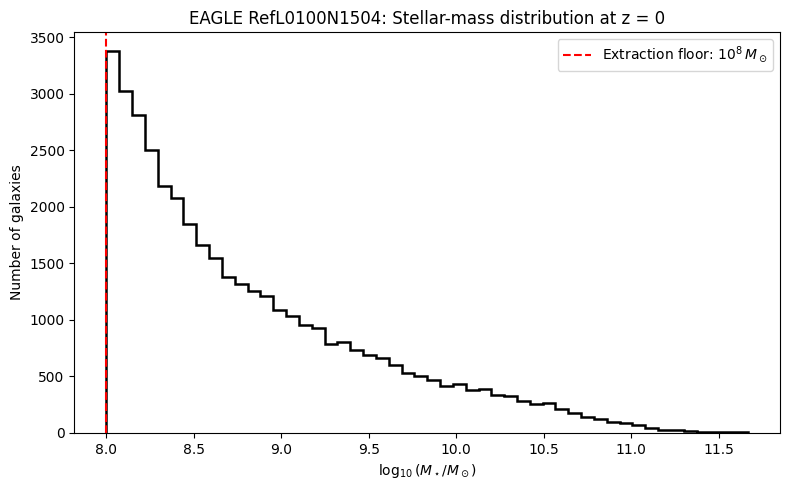

In [16]:
eagle["logMstar"] = np.log10(
    eagle["Mstar_30pkpc"]
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    eagle["logMstar"],
    bins=50,
    histtype="step",
    linewidth=1.8,
    color="black"
)

ax.axvline(
    8.0,
    linestyle="--",
    color="red",
    label=r"Extraction floor: $10^8\,M_\odot$"
)

ax.set_xlabel(
    r"$\log_{10}(M_\star/M_\odot)$"
)

ax.set_ylabel("Number of galaxies")

ax.set_title(
    "EAGLE RefL0100N1504: "
    "Stellar-mass distribution at z = 0"
)

ax.legend()

plt.tight_layout()
plt.show()

In [17]:
# Candidate stellar-mass thresholds
log_mass_limits = np.array([
    8.0, 8.5, 9.0, 9.5, 10.0
])

# EAGLE box volume in comoving Mpc^3
box_volume = BOX_SIZE_CMPC**3

# GW190814 90% HPD-equivalent volume
mock_volume = V90

results = []

for log_limit in log_mass_limits:

    mass_limit = 10**log_limit

    selected = eagle[
        eagle["Mstar_30pkpc"] > mass_limit
    ]

    n_galaxies = len(selected)

    number_density = n_galaxies / box_volume

    # Mean expected count in an equivalent volume
    expected_count = number_density * mock_volume

    results.append({
        "logM_limit": log_limit,
        "N_box": n_galaxies,
        "number_density_cMpc3": number_density,
        "expected_N_mock": expected_count
    })

threshold_df = pd.DataFrame(results)

display(
    threshold_df.round({
        "number_density_cMpc3": 5,
        "expected_N_mock": 1
    })
)

,logM_limit,N_box,number_density_cMpc3,expected_N_mock
0,8.0,40076,0.04008,1269.0
1,8.5,22580,0.02258,715.0
2,9.0,13200,0.01320,418.0
3,9.5,7241,0.00724,229.3
4,10.0,3562,0.00356,112.8


In [18]:
# Provisional primary stellar-mass threshold
LOG_MASS_MIN = 9.0
MASS_MIN = 10**LOG_MASS_MIN

# Select galaxies above threshold
eagle_science = eagle.loc[
    eagle["Mstar_30pkpc"] >= MASS_MIN
].copy()

# Fix random seed for reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Cube side length from GW190814 3D volume
L = V90**(1 / 3)

# Uniformly position the cube entirely inside
# the EAGLE simulation box
cube_origin = rng.uniform(
    0,
    BOX_SIZE_CMPC - L,
    size=3
)

cube_upper = cube_origin + L

# Select galaxies within the cube
position_columns = ["x", "y", "z"]
positions = eagle_science[position_columns].to_numpy()

inside = np.all(
    (positions >= cube_origin)
    & (positions < cube_upper),
    axis=1
)

reference_cube = eagle_science.loc[inside].copy()

print("REFERENCE EAGLE CUBE")
print("-" * 45)
print(f"Random seed: {RANDOM_SEED}")
print(f"Stellar-mass threshold: 10^{LOG_MASS_MIN:.1f} Msun")
print(f"Cube side length: {L:.3f} cMpc")
print(f"Cube volume: {L**3:,.2f} cMpc³")
print(f"Cube origin: {cube_origin.round(3)}")
print(f"Galaxies selected: {len(reference_cube):,}")

display(reference_cube.head())

REFERENCE EAGLE CUBE
---------------------------------------------
Random seed: 42
Stellar-mass threshold: 10^9.0 Msun
Cube side length: 31.637 cMpc
Cube volume: 31,665.93 cMpc³
Cube origin: [52.91  30.003 58.696]
Galaxies selected: 402


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,Mgas_30pkpc,SFR_30pkpc,GroupID,SubGroupNumber,logMstar
60,10552361,28,60.770462,52.978657,61.237030,8.358051e+09,1.768751e+09,0.167142,28000000002416,0,9.922105
97,11627402,28,70.228203,57.523304,70.545975,1.355766e+09,1.381578e+09,0.147639,28000000003524,0,9.132185
111,11869398,28,60.769066,49.078812,68.758797,1.388122e+09,1.493911e+09,0.049733,28000000003984,0,9.142427
117,11937811,28,61.499798,51.902168,64.761932,2.982138e+09,2.377083e+09,0.407484,28000000004120,0,9.474527
160,12617264,28,58.979069,47.380344,73.033081,2.837739e+09,1.586292e+09,0.175095,28000000005434,0,9.452972


In [19]:
# Confirm that the reference cube satisfies
# all of our selection requirements.

assert reference_cube["GalaxyID"].is_unique

assert (
    reference_cube["Mstar_30pkpc"] >= MASS_MIN
).all()

assert np.all(
    (reference_cube[["x", "y", "z"]].to_numpy()
     >= cube_origin)
    &
    (reference_cube[["x", "y", "z"]].to_numpy()
     < cube_upper)
)

# Summarise the galaxy population

n_gal = len(reference_cube)
n_zero_sfr = (reference_cube["SFR_30pkpc"] == 0).sum()

summary = pd.Series({
    "Galaxy count": n_gal,
    "Number density (cMpc^-3)": n_gal / V90,
    "Median log stellar mass": reference_cube["logMstar"].median(),
    "Maximum log stellar mass": reference_cube["logMstar"].max(),
    "Median SFR (Msun/yr)": reference_cube["SFR_30pkpc"].median(),
    "Zero-SFR fraction": n_zero_sfr / n_gal,
    "Distinct GroupIDs": reference_cube["GroupID"].nunique()
})

display(summary.to_frame("Value"))

,Value
Galaxy count,402.000000
Number density (cMpc^-3),0.012695
Median log stellar mass,9.538293
Maximum log stellar mass,11.410273
Median SFR (Msun/yr),0.133528
Zero-SFR fraction,0.181592
Distinct GroupIDs,237.000000


In [20]:
# Save the actual reference galaxy population
reference_path = DATA / "EAGLE_reference_cube_seed42.csv"

reference_cube.to_csv(
    reference_path,
    index=False
)

# Record the exact configuration
cube_config = {
    "simulation": SIMULATION,
    "snapshot": SNAPSHOT,
    "redshift": 0.0,
    "stellar_mass_threshold_msun": float(MASS_MIN),
    "random_seed": RANDOM_SEED,
    "box_size_comoving_mpc": BOX_SIZE_CMPC,
    "cube_origin_comoving_mpc": cube_origin.tolist(),
    "cube_upper_comoving_mpc": cube_upper.tolist(),
    "cube_side_comoving_mpc": float(L),
    "cube_volume_comoving_mpc3": float(L**3),
    "galaxy_count": int(len(reference_cube)),
    "boundary_handling": "cube entirely inside simulation box"
}

config_path = DATA / "EAGLE_reference_cube_config.json"

with open(config_path, "w") as f:
    json.dump(cube_config, f, indent=2)

print("Reference cube saved:", reference_path)
print("Configuration saved:", config_path)

Reference cube saved: data/EAGLE_reference_cube_seed42.csv
Configuration saved: data/EAGLE_reference_cube_config.json


In [21]:
def sample_periodic_cube(
    catalogue,
    origin,
    side_length,
    box_size=100.0
):
    """
    Select galaxies inside a cube in a periodic
    cosmological simulation box.

    Parameters
    ----------
    catalogue : pandas.DataFrame
        Galaxy catalogue containing x, y, z.
    origin : array-like, length 3
        Cube origin in comoving Mpc.
    side_length : float
        Cube side length in comoving Mpc.
    box_size : float
        Simulation box side length in comoving Mpc.

    Returns
    -------
    pandas.DataFrame
        Galaxies contained in the periodic cube.
    """

    origin = np.asarray(origin, dtype=float)

    assert origin.shape == (3,)
    assert 0 < side_length <= box_size

    positions = catalogue[
        ["x", "y", "z"]
    ].to_numpy(dtype=float)

    # Position relative to the cube origin,
    # wrapping across periodic boundaries
    relative = (
        positions - origin
    ) % box_size

    inside = np.all(
        relative < side_length,
        axis=1
    )

    return catalogue.loc[inside].copy()

In [22]:
# Repeat reference cube selection using
# the periodic implementation

periodic_reference = sample_periodic_cube(
    catalogue=eagle_science,
    origin=cube_origin,
    side_length=L,
    box_size=BOX_SIZE_CMPC
)

original_ids = set(reference_cube["GalaxyID"])
periodic_ids = set(periodic_reference["GalaxyID"])

assert original_ids == periodic_ids, (
    "Periodic and non-periodic selections differ."
)

print("PASS: Periodic selection reproduces reference cube.")
print("Galaxy count:", len(periodic_reference))

PASS: Periodic selection reproduces reference cube.
Galaxy count: 402


In [23]:
# Artificial catalogue for boundary testing
test_galaxies = pd.DataFrame({
    "GalaxyID": [1, 2, 3, 4],
    "x": [98.0, 2.0, 50.0, 99.0],
    "y": [98.0, 2.0, 50.0, 1.0],
    "z": [98.0, 2.0, 50.0, 99.0]
})

# Cube extends from 95 to 105 on each axis,
# wrapping around the 100 cMpc boundary.
test_cube = sample_periodic_cube(
    catalogue=test_galaxies,
    origin=[95.0, 95.0, 95.0],
    side_length=10.0,
    box_size=100.0
)

# Galaxies 1, 2 and 4 should be included.
assert set(test_cube["GalaxyID"]) == {1, 2, 4}

print("PASS: Periodic boundary wrapping works correctly.")

PASS: Periodic boundary wrapping works correctly.


In [24]:
N_CUBES = 500
ENSEMBLE_SEED = 12345

rng = np.random.default_rng(ENSEMBLE_SEED)

cube_records = []

for cube_id in range(N_CUBES):

    origin = rng.uniform(
        0,
        BOX_SIZE_CMPC,
        size=3
    )

    mock = sample_periodic_cube(
        catalogue=eagle_science,
        origin=origin,
        side_length=L,
        box_size=BOX_SIZE_CMPC
    )

    n = len(mock)

    cube_records.append({
        "cube_id": cube_id,
        "origin_x": origin[0],
        "origin_y": origin[1],
        "origin_z": origin[2],
        "N_galaxies": n,
        "number_density": n / V90,
        "median_logMstar": (
            mock["logMstar"].median()
            if n > 0 else np.nan
        ),
        "median_SFR": (
            mock["SFR_30pkpc"].median()
            if n > 0 else np.nan
        ),
        "zero_SFR_fraction": (
            (mock["SFR_30pkpc"] == 0).mean()
            if n > 0 else np.nan
        ),
        "total_stellar_mass": (
            mock["Mstar_30pkpc"].sum()
        ),
        "total_SFR": (
            mock["SFR_30pkpc"].sum()
        )
    })

ensemble = pd.DataFrame(cube_records)

assert len(ensemble) == N_CUBES
assert ensemble["N_galaxies"].ge(0).all()

display(ensemble.head())

print(f"\nGenerated {N_CUBES} periodic mock volumes.")

,cube_id,origin_x,origin_y,origin_z,N_galaxies,number_density,median_logMstar,median_SFR,zero_SFR_fraction,total_stellar_mass,total_SFR
0,0,22.733602,31.675834,79.736546,440,0.013895,9.595505,0.154030,0.161364,5.031541e+12,159.328857
1,1,67.625467,39.110955,33.281393,647,0.020432,9.564050,0.125409,0.204019,8.303957e+12,254.166382
2,2,59.830875,18.673419,67.275604,335,0.010579,9.570224,0.167062,0.110448,4.146894e+12,141.501801
3,3,94.180287,24.824571,94.888115,234,0.007390,9.484066,0.193414,0.102564,2.251755e+12,93.595169
4,4,66.723745,9.589794,44.183967,532,0.016800,9.563738,0.152211,0.184211,6.533456e+12,257.141052



Generated 500 periodic mock volumes.


In [25]:
summary_for_writeup = pd.DataFrame({
    "Property": [
        "Number of galaxies",
        r"Median $\log_{10}(M_\star/M_\odot)$",
        r"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",
        "Zero-SFR fraction",
        r"Total stellar mass ($M_\odot$)",
        r"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)"
    ],
    "Median": [
        ensemble["N_galaxies"].median(),
        ensemble["median_logMstar"].median(),
        ensemble["median_SFR"].median(),
        ensemble["zero_SFR_fraction"].median(),
        ensemble["total_stellar_mass"].median(),
        ensemble["total_SFR"].median()
    ],
    "16th percentile": [
        ensemble["N_galaxies"].quantile(0.16),
        ensemble["median_logMstar"].quantile(0.16),
        ensemble["median_SFR"].quantile(0.16),
        ensemble["zero_SFR_fraction"].quantile(0.16),
        ensemble["total_stellar_mass"].quantile(0.16),
        ensemble["total_SFR"].quantile(0.16)
    ],
    "84th percentile": [
        ensemble["N_galaxies"].quantile(0.84),
        ensemble["median_logMstar"].quantile(0.84),
        ensemble["median_SFR"].quantile(0.84),
        ensemble["zero_SFR_fraction"].quantile(0.84),
        ensemble["total_stellar_mass"].quantile(0.84),
        ensemble["total_SFR"].quantile(0.84)
    ],
    "Minimum": [
        ensemble["N_galaxies"].min(),
        ensemble["median_logMstar"].min(),
        ensemble["median_SFR"].min(),
        ensemble["zero_SFR_fraction"].min(),
        ensemble["total_stellar_mass"].min(),
        ensemble["total_SFR"].min()
    ],
    "Maximum": [
        ensemble["N_galaxies"].max(),
        ensemble["median_logMstar"].max(),
        ensemble["median_SFR"].max(),
        ensemble["zero_SFR_fraction"].max(),
        ensemble["total_stellar_mass"].max(),
        ensemble["total_SFR"].max()
    ]
})

summary_for_writeup

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,Number of galaxies,3.805000e+02,2.156800e+02,6.226400e+02,8.100000e+01,1.426000e+03
1,Median $\log_{10}(M_\star/M_\odot)$,9.563968e+00,9.517296e+00,9.600317e+00,9.340024e+00,9.693915e+00
2,"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",1.523377e-01,1.005304e-01,1.862919e-01,0.000000e+00,2.489420e-01
3,Zero-SFR fraction,1.692781e-01,8.568421e-02,2.989430e-01,6.172840e-03,5.361184e-01
4,Total stellar mass ($M_\odot$),4.570324e+12,2.182685e+12,7.972172e+12,6.721946e+11,2.087515e+13
5,"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)",1.564683e+02,8.629304e+01,2.464690e+02,2.306959e+01,4.884771e+02


In [26]:
summary_display = summary_for_writeup.copy()

summary_display.loc[0, summary_display.columns[1:]] = summary_display.loc[0, summary_display.columns[1:]].round(0)
summary_display.loc[1, summary_display.columns[1:]] = summary_display.loc[1, summary_display.columns[1:]].round(3)
summary_display.loc[2, summary_display.columns[1:]] = summary_display.loc[2, summary_display.columns[1:]].round(3)
summary_display.loc[3, summary_display.columns[1:]] = summary_display.loc[3, summary_display.columns[1:]].round(3)
summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
summary_display.loc[5, summary_display.columns[1:]] = summary_display.loc[5, summary_display.columns[1:]].round(2)

display(summary_display)

/tmp/ipykernel_1797/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '4.57e+12' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
/tmp/ipykernel_1797/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2.18e+12' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
/tmp/ipykernel_1797/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '7.97e+12' has dtype incompatible with f

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,Number of galaxies,380.5,215.68,622.64,81.0,1426.0
1,Median $\log_{10}(M_\star/M_\odot)$,9.563968,9.517296,9.600317,9.340024,9.693915
2,"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",0.152338,0.10053,0.186292,0.0,0.248942
3,Zero-SFR fraction,0.169278,0.085684,0.298943,0.006173,0.536118
4,Total stellar mass ($M_\odot$),4.57e+12,2.18e+12,7.97e+12,6.72e+11,2.09e+13
5,"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)",156.468292,86.293039,246.469045,23.069588,488.477051


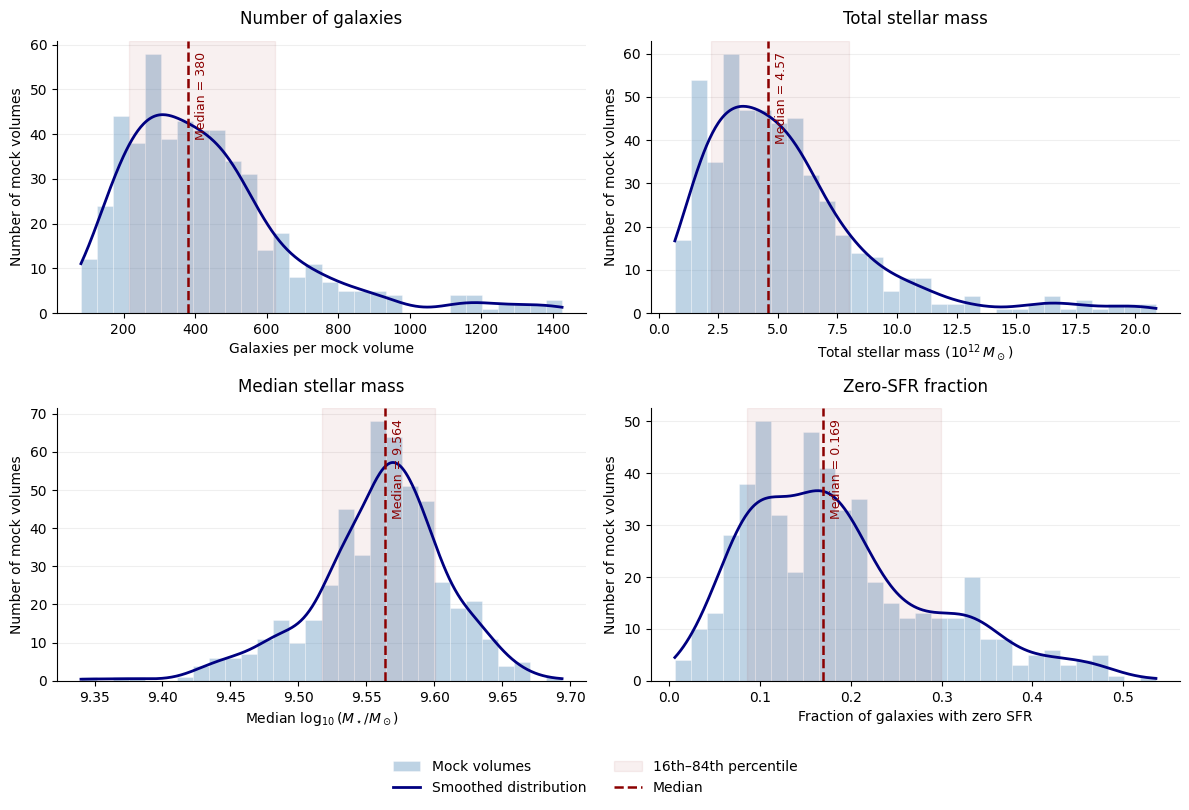

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# --------------------------------------------------
# Configuration
# --------------------------------------------------

plot_specs = [
    {
        "column": "N_galaxies",
        "title": "Number of galaxies",
        "xlabel": "Galaxies per mock volume",
        "scale": 1,
        "precision": 0
    },
    {
        "column": "total_stellar_mass",
        "title": "Total stellar mass",
        "xlabel": r"Total stellar mass ($10^{12}\,M_\odot$)",
        "scale": 1e12,
        "precision": 2
    },
    {
        "column": "median_logMstar",
        "title": "Median stellar mass",
        "xlabel": r"Median $\log_{10}(M_\star/M_\odot)$",
        "scale": 1,
        "precision": 3
    },
    {
        "column": "zero_SFR_fraction",
        "title": "Zero-SFR fraction",
        "xlabel": "Fraction of galaxies with zero SFR",
        "scale": 1,
        "precision": 3
    }
]

# --------------------------------------------------
# Create figure
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8)
)

for ax, spec in zip(axes.flat, plot_specs):

    values = (
        ensemble[spec["column"]]
        .dropna()
        .to_numpy(dtype=float)
        / spec["scale"]
    )

    # Summary statistics
    median = np.median(values)
    p16, p84 = np.percentile(values, [16, 84])

    # Histogram: actual number of mock volumes
    counts, edges, _ = ax.hist(
        values,
        bins=30,
        color="steelblue",
        alpha=0.35,
        edgecolor="white",
        linewidth=0.7,
        label="Mock volumes"
    )

    # Kernel density estimate
    kde = gaussian_kde(values)

    x_grid = np.linspace(
        values.min(),
        values.max(),
        500
    )

    # Convert KDE density into expected bin counts
    bin_width = np.mean(np.diff(edges))

    kde_counts = (
        kde(x_grid)
        * len(values)
        * bin_width
    )

    ax.plot(
        x_grid,
        kde_counts,
        color="navy",
        linewidth=2,
        label="Smoothed distribution"
    )

    # Central 68% interval
    ax.axvspan(
        p16,
        p84,
        color="darkred",
        alpha=0.06,
        label="16th–84th percentile"
    )

    # Median line
    ax.axvline(
        median,
        color="darkred",
        linewidth=1.8,
        linestyle="--",
        label="Median"
    )

    # --------------------------------------------------
    # Numerical median label
    # --------------------------------------------------

    precision = spec["precision"]

    median_label = (
        f"Median = {median:.{precision}f}"
    )

    # Position label near the top of the line
    ax.annotate(
        median_label,
        xy=(median, 0.96),
        xycoords=ax.get_xaxis_transform(),
        xytext=(5, 0),
        textcoords="offset points",
        rotation=90,
        ha="left",
        va="top",
        fontsize=9,
        color="darkred"
    )

    # --------------------------------------------------
    # Formatting
    # --------------------------------------------------

    ax.set_title(
        spec["title"],
        fontsize=12,
        pad=12
    )

    ax.set_xlabel(spec["xlabel"])
    ax.set_ylabel("Number of mock volumes")

    ax.grid(
        axis="y",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.015)
)

# No overall figure title:
# the dissertation figure caption will serve
# that purpose.

plt.tight_layout(
    rect=[0, 0.065, 1, 1]
)

# --------------------------------------------------
# Save high-resolution outputs
# --------------------------------------------------

fig.savefig(
    "EAGLE_population_distributions.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "EAGLE_population_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
from scipy.stats import spearmanr

mass_thresholds = [8.0, 8.5, 9.0, 9.5]

threshold_records = []

# Use EXACTLY the same 500 cube origins
# to isolate the effect of changing the mass threshold.

for log_limit in mass_thresholds:

    catalogue = eagle.loc[
        eagle["Mstar_30pkpc"] >= 10**log_limit
    ].copy()

    for _, row in ensemble.iterrows():

        origin = row[
            ["origin_x", "origin_y", "origin_z"]
        ].to_numpy(dtype=float)

        mock = sample_periodic_cube(
            catalogue,
            origin,
            L,
            BOX_SIZE_CMPC
        )

        n = len(mock)

        threshold_records.append({
            "threshold": log_limit,
            "cube_id": int(row["cube_id"]),
            "N_galaxies": n,
            "zero_SFR_fraction": (
                (mock["SFR_30pkpc"] == 0).mean()
                if n > 0 else np.nan
            ),
            "median_logMstar": (
                np.log10(mock["Mstar_30pkpc"]).median()
                if n > 0 else np.nan
            ),
            "total_stellar_mass": mock["Mstar_30pkpc"].sum(),
            "total_SFR": mock["SFR_30pkpc"].sum()
        })

threshold_results = pd.DataFrame(threshold_records)

summary_records = []

for limit, group in threshold_results.groupby("threshold"):

    rho, _ = spearmanr(
        group["N_galaxies"],
        group["zero_SFR_fraction"],
        nan_policy="omit"
    )

    summary_records.append({
        "logM_min": limit,
        "median_N": group["N_galaxies"].median(),
        "N_16": group["N_galaxies"].quantile(0.16),
        "N_84": group["N_galaxies"].quantile(0.84),
        "median_zero_SFR_fraction":
            group["zero_SFR_fraction"].median(),
        "Spearman_rho": rho
    })

threshold_summary = pd.DataFrame(summary_records)

display(threshold_summary.round(3))

threshold_results.to_csv(
    DATA / "EAGLE_mass_threshold_sensitivity.csv",
    index=False
)

,logM_min,median_N,N_16,N_84,median_zero_SFR_fraction,Spearman_rho
0,8.0,1182.5,682.84,1839.80,0.375,0.893
1,8.5,664.0,382.52,1051.44,0.244,0.871
2,9.0,380.5,215.68,622.64,0.169,0.843
3,9.5,215.0,110.84,333.16,0.130,0.808


In [29]:
# ============================================================
# CELL 33
# Stellar-mass threshold sensitivity:
# retained stellar mass and star formation
# ============================================================

import numpy as np
import pandas as pd

MASS_THRESHOLDS = [8.0, 8.5, 9.0, 9.5]

# ------------------------------------------------------------
# 1. Retained fractions across the full EAGLE parent catalogue
# ------------------------------------------------------------

parent_total_mass = eagle["Mstar_30pkpc"].sum()
parent_total_sfr = eagle["SFR_30pkpc"].sum()
parent_count = len(eagle)

box_records = []

for log_limit in MASS_THRESHOLDS:

    selected = eagle.loc[
        eagle["Mstar_30pkpc"] >= 10**log_limit
    ]

    box_records.append({
        "logM_min": log_limit,
        "N_galaxies": len(selected),
        "galaxies_retained_pct":
            100 * len(selected) / parent_count,
        "stellar_mass_retained_pct":
            100 * selected["Mstar_30pkpc"].sum()
            / parent_total_mass,
        "SFR_retained_pct":
            100 * selected["SFR_30pkpc"].sum()
            / parent_total_sfr
    })

box_retention = pd.DataFrame(box_records)

print("FULL EAGLE BOX: RETAINED FRACTIONS")
display(box_retention.round(2))


# ------------------------------------------------------------
# 2. Retained fractions within each of the 500 mock volumes
# ------------------------------------------------------------

cube_records = []

for _, row in ensemble.iterrows():

    origin = row[
        ["origin_x", "origin_y", "origin_z"]
    ].to_numpy(dtype=float)

    # Extract the full parent population above 10^8 Msun
    mock_parent = sample_periodic_cube(
        catalogue=eagle,
        origin=origin,
        side_length=L,
        box_size=BOX_SIZE_CMPC
    )

    reference_mass = mock_parent["Mstar_30pkpc"].sum()
    reference_sfr = mock_parent["SFR_30pkpc"].sum()
    reference_count = len(mock_parent)

    for log_limit in MASS_THRESHOLDS:

        selected = mock_parent.loc[
            mock_parent["Mstar_30pkpc"] >= 10**log_limit
        ]

        cube_records.append({
            "cube_id": int(row["cube_id"]),
            "logM_min": log_limit,

            "galaxies_retained_pct":
                100 * len(selected) / reference_count
                if reference_count > 0 else np.nan,

            "stellar_mass_retained_pct":
                100 * selected["Mstar_30pkpc"].sum()
                / reference_mass
                if reference_mass > 0 else np.nan,

            "SFR_retained_pct":
                100 * selected["SFR_30pkpc"].sum()
                / reference_sfr
                if reference_sfr > 0 else np.nan
        })

cube_retention = pd.DataFrame(cube_records)


# ------------------------------------------------------------
# 3. Summarise variation between mock volumes
# ------------------------------------------------------------

summary_records = []

for log_limit, group in cube_retention.groupby("logM_min"):

    record = {"logM_min": log_limit}

    for column in [
        "galaxies_retained_pct",
        "stellar_mass_retained_pct",
        "SFR_retained_pct"
    ]:

        values = group[column].dropna()

        record[column + "_median"] = values.median()
        record[column + "_p16"] = values.quantile(0.16)
        record[column + "_p84"] = values.quantile(0.84)

    summary_records.append(record)

retention_summary = pd.DataFrame(summary_records)

print("\n500 MOCK VOLUMES: RETAINED FRACTIONS")
display(retention_summary.round(2))


# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------

box_retention.to_csv(
    DATA / "EAGLE_box_mass_threshold_retention.csv",
    index=False
)

cube_retention.to_csv(
    DATA / "EAGLE_cube_mass_threshold_retention.csv",
    index=False
)

retention_summary.to_csv(
    DATA / "EAGLE_mass_threshold_retention_summary.csv",
    index=False
)

print("\nRetention analysis completed and saved.")

FULL EAGLE BOX: RETAINED FRACTIONS


,logM_min,N_galaxies,galaxies_retained_pct,stellar_mass_retained_pct,SFR_retained_pct
0,8.0,40076,100.00,100.000000,100.000000
1,8.5,22580,56.34,98.180000,97.290001
2,9.0,13200,32.94,95.029999,92.480003
3,9.5,7241,18.07,88.709999,81.459999



500 MOCK VOLUMES: RETAINED FRACTIONS


,logM_min,galaxies_retained_pct_median,galaxies_retained_pct_p16,galaxies_retained_pct_p84,stellar_mass_retained_pct_median,stellar_mass_retained_pct_p16,stellar_mass_retained_pct_p84,SFR_retained_pct_median,SFR_retained_pct_p16,SFR_retained_pct_p84
0,8.0,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,8.5,56.05,54.07,57.83,98.09,97.64,98.38,97.47,96.32,98.03
2,9.0,32.72,30.75,34.47,94.83,93.77,95.53,92.23,90.05,93.71
3,9.5,17.84,16.01,19.11,88.37,85.79,89.63,80.85,76.49,83.63



Retention analysis completed and saved.


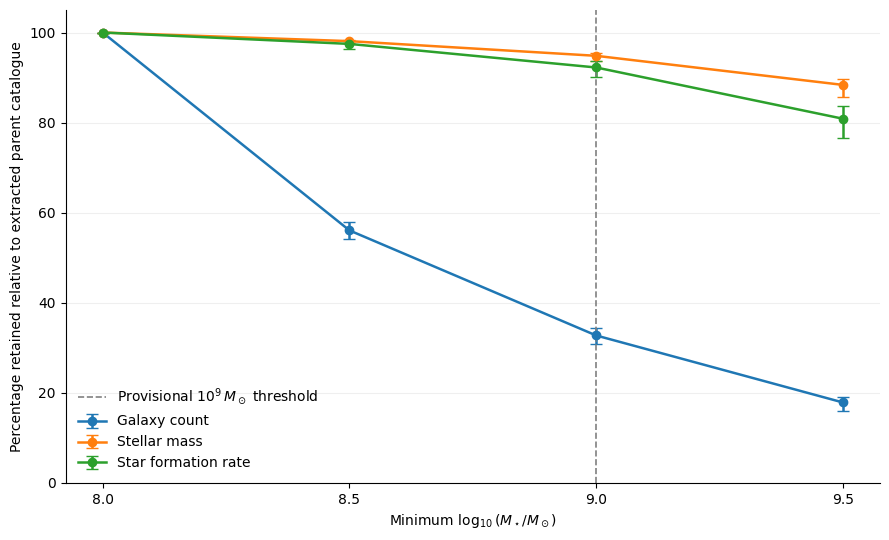

In [30]:
# ============================================================
# CELL 34
# Visualise galaxy, stellar-mass and SFR retention
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5.5))

properties = [
    ("galaxies_retained_pct", "Galaxy count"),
    ("stellar_mass_retained_pct", "Stellar mass"),
    ("SFR_retained_pct", "Star formation rate")
]

for column, label in properties:

    medians = retention_summary[
        column + "_median"
    ].to_numpy()

    lower = retention_summary[
        column + "_p16"
    ].to_numpy()

    upper = retention_summary[
        column + "_p84"
    ].to_numpy()

    ax.errorbar(
        retention_summary["logM_min"],
        medians,
        yerr=[
            medians - lower,
            upper - medians
        ],
        marker="o",
        markersize=6,
        linewidth=1.8,
        capsize=4,
        label=label
    )

# Indicate our provisional threshold
ax.axvline(
    9.0,
    color="grey",
    linestyle="--",
    linewidth=1.2,
    label=r"Provisional $10^9\,M_\odot$ threshold"
)

ax.set_xlabel(
    r"Minimum $\log_{10}(M_\star/M_\odot)$"
)

ax.set_ylabel(
    "Percentage retained relative to extracted parent catalogue"
)

ax.set_ylim(0, 105)

ax.set_xticks(MASS_THRESHOLDS)

ax.grid(
    axis="y",
    alpha=0.2
)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig.savefig(
    "EAGLE_stellar_mass_threshold_retention.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "EAGLE_stellar_mass_threshold_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
properties = [
    "N_galaxies",
    "median_logMstar",
    "median_SFR",
    "zero_SFR_fraction",
    "total_stellar_mass",
    "total_SFR"
]

summary_rows = []

for name in properties:

    values = ensemble[name].dropna()

    summary_rows.append({
        "Property": name,
        "Median": values.median(),
        "16th percentile": values.quantile(0.16),
        "84th percentile": values.quantile(0.84),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

ensemble_summary = pd.DataFrame(summary_rows)

display(ensemble_summary)

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,N_galaxies,3.805000e+02,2.156800e+02,6.226400e+02,8.100000e+01,1.426000e+03
1,median_logMstar,9.563968e+00,9.517296e+00,9.600317e+00,9.340024e+00,9.693915e+00
2,median_SFR,1.523377e-01,1.005304e-01,1.862919e-01,0.000000e+00,2.489420e-01
3,zero_SFR_fraction,1.692781e-01,8.568421e-02,2.989430e-01,6.172840e-03,5.361184e-01
4,total_stellar_mass,4.570324e+12,2.182685e+12,7.972172e+12,6.721946e+11,2.087515e+13
5,total_SFR,1.564683e+02,8.629304e+01,2.464690e+02,2.306959e+01,4.884771e+02


In [32]:
ensemble_path = DATA / "EAGLE_500_periodic_mock_volumes.csv"

ensemble.to_csv(
    ensemble_path,
    index=False
)

ensemble_config = {
    "simulation": SIMULATION,
    "snapshot": SNAPSHOT,
    "number_of_cubes": N_CUBES,
    "random_seed": ENSEMBLE_SEED,
    "stellar_mass_threshold_msun": float(MASS_MIN),
    "cube_side_comoving_mpc": float(L),
    "cube_volume_comoving_mpc3": float(V90),
    "simulation_box_side_comoving_mpc": BOX_SIZE_CMPC,
    "sampling": "uniform random origins with periodic wrapping",
    "overlap_allowed": True
}

with open(
    DATA / "EAGLE_500_periodic_mock_volumes_config.json",
    "w"
) as f:
    json.dump(ensemble_config, f, indent=2)

print("Saved:", ensemble_path)

Saved: data/EAGLE_500_periodic_mock_volumes.csv


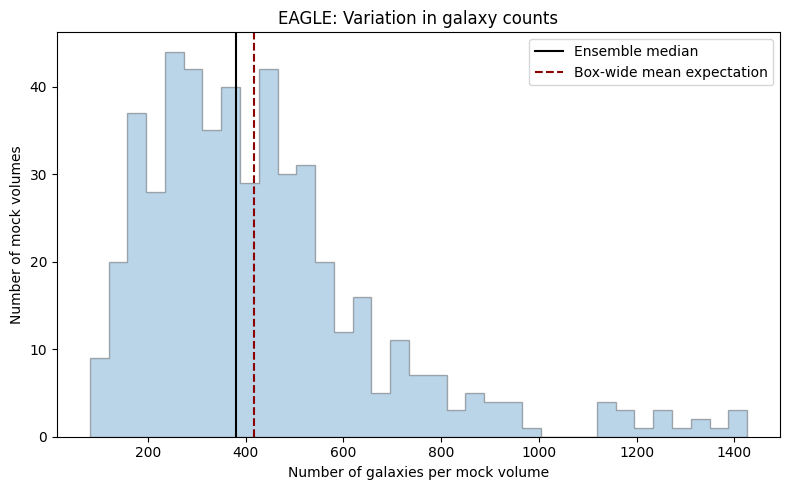

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    ensemble["N_galaxies"],
    bins=35,
    histtype="stepfilled",
    alpha=0.3,
    edgecolor="black"
)

ax.axvline(
    ensemble["N_galaxies"].median(),
    color="black",
    linewidth=1.5,
    label="Ensemble median"
)

ax.axvline(
    threshold_df.loc[
        threshold_df["logM_limit"] == 9.0,
        "expected_N_mock"
    ].iloc[0],
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label="Box-wide mean expectation"
)

ax.set_xlabel("Number of galaxies per mock volume")
ax.set_ylabel("Number of mock volumes")
ax.set_title("EAGLE: Variation in galaxy counts")

ax.legend()
plt.tight_layout()
plt.show()

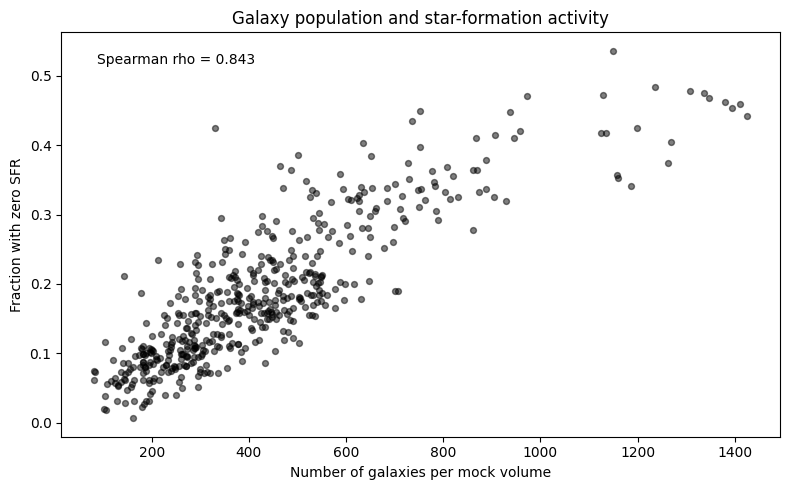

Spearman correlation: 0.8428
Nominal p-value: 4.345e-136


In [34]:
from scipy.stats import spearmanr

x = ensemble["N_galaxies"]
y = ensemble["zero_SFR_fraction"]

rho, p_value = spearmanr(x, y)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x,
    y,
    s=18,
    alpha=0.5,
    color="black"
)

ax.set_xlabel("Number of galaxies per mock volume")
ax.set_ylabel("Fraction with zero SFR")
ax.set_title("Galaxy population and star-formation activity")

ax.text(
    0.05,
    0.95,
    f"Spearman rho = {rho:.3f}",
    transform=ax.transAxes,
    va="top"
)

plt.tight_layout()
plt.show()

print(f"Spearman correlation: {rho:.4f}")
print(f"Nominal p-value: {p_value:.4g}")

In [35]:
mass_bins = [
    (9.0, 9.5),
    (9.5, 10.0),
    (10.0, 10.5),
    (10.5, np.inf)
]

records = []

for _, cube in ensemble.iterrows():

    origin = cube[
        ["origin_x", "origin_y", "origin_z"]
    ].to_numpy(dtype=float)

    mock = sample_periodic_cube(
        eagle_science,
        origin,
        L,
        BOX_SIZE_CMPC
    )

    for lower, upper in mass_bins:

        subset = mock[
            (mock["logMstar"] >= lower)
            & (mock["logMstar"] < upper)
        ]

        records.append({
            "cube_id": int(cube["cube_id"]),
            "N_galaxies": len(mock),
            "mass_bin": f"{lower:.1f}–{upper:.1f}",
            "N_in_bin": len(subset),
            "zero_SFR_fraction": (
                (subset["SFR_30pkpc"] == 0).mean()
                if len(subset) > 0 else np.nan
            )
        })

mass_bin_results = pd.DataFrame(records)

for mass_bin, group in mass_bin_results.groupby("mass_bin"):

    valid_group = group[
        group["N_in_bin"] >= 10
    ].dropna()

    rho, p = spearmanr(
        valid_group["N_galaxies"],
        valid_group["zero_SFR_fraction"]
    )

    print(
        f"{mass_bin}: "
        f"rho={rho:.3f}, "
        f"cubes={len(valid_group)}"
    )

10.0–10.5: rho=0.696, cubes=499
10.5–inf: rho=0.561, cubes=484
9.0–9.5: rho=0.838, cubes=500
9.5–10.0: rho=0.799, cubes=500


In [36]:
# ============================================================
# CELL 37
# Flat, stellar-mass and SFR host priors
# ============================================================

import numpy as np
import pandas as pd


def normalise_host_weights(weights):
    """
    Convert non-negative astrophysical host weights
    into normalised relative host probabilities.

    The resulting probabilities must sum to unity.
    """

    weights = np.asarray(weights, dtype=float)

    if weights.ndim != 1 or len(weights) == 0:
        raise ValueError("Weights must be a non-empty 1D array.")

    if not np.all(np.isfinite(weights)):
        raise ValueError("Host weights contain non-finite values.")

    if np.any(weights < 0):
        raise ValueError("Host weights cannot be negative.")

    # Scaling prevents overflow when summing large weights.
    scale = np.max(weights)

    if scale <= 0:
        raise ValueError(
            "All host weights are zero; "
            "this prior cannot be normalised."
        )

    scaled_weights = weights / scale
    probabilities = scaled_weights / scaled_weights.sum()

    np.testing.assert_allclose(
        probabilities.sum(),
        1.0,
        rtol=1e-12,
        atol=1e-12
    )

    return probabilities


def apply_host_priors(catalogue):
    """
    Apply three host-prior models to an EAGLE
    mock galaxy population.

    Returns the galaxy catalogue with additional
    columns containing normalised probabilities.
    """

    result = catalogue.copy()

    if result.empty:
        raise ValueError("The mock volume contains no galaxies.")

    if not result["GalaxyID"].is_unique:
        raise ValueError("Duplicate galaxy IDs detected.")

    # Raw astrophysical host weights
    flat_weights = np.ones(len(result), dtype=float)

    mass_weights = result[
        "Mstar_30pkpc"
    ].to_numpy(dtype=float)

    sfr_weights = result[
        "SFR_30pkpc"
    ].to_numpy(dtype=float)

    # Normalised relative probabilities
    result["P_flat"] = normalise_host_weights(
        flat_weights
    )

    result["P_mass"] = normalise_host_weights(
        mass_weights
    )

    result["P_SFR"] = normalise_host_weights(
        sfr_weights
    )

    return result

In [37]:
# ============================================================
# CELL 38
# Controlled test of host-prior normalisation
# ============================================================

test_sample = pd.DataFrame({
    "GalaxyID": [1, 2, 3],
    "Mstar_30pkpc": [1e9, 2e9, 7e9],
    "SFR_30pkpc": [0.0, 1.0, 3.0]
})

test_result = apply_host_priors(test_sample)

# Flat prior: every galaxy receives 1/3
np.testing.assert_allclose(
    test_result["P_flat"],
    [1/3, 1/3, 1/3]
)

# Mass prior: masses in the ratio 1:2:7
np.testing.assert_allclose(
    test_result["P_mass"],
    [0.1, 0.2, 0.7]
)

# SFR prior: SFR in the ratio 0:1:3
np.testing.assert_allclose(
    test_result["P_SFR"],
    [0.0, 0.25, 0.75]
)

display(
    test_result[
        ["GalaxyID", "P_flat", "P_mass", "P_SFR"]
    ]
)

print("PASS: All three prior calculations are correct.")

,GalaxyID,P_flat,P_mass,P_SFR
0,1,0.333333,0.1,0.00
1,2,0.333333,0.2,0.25
2,3,0.333333,0.7,0.75


PASS: All three prior calculations are correct.


In [38]:
# ============================================================
# CELL 39
# Apply host priors to the reference EAGLE cube
# ============================================================

reference_probabilities = apply_host_priors(
    reference_cube
)

print("REFERENCE CUBE HOST-PRIOR VALIDATION")
print("-" * 50)

print("Galaxies:", len(reference_probabilities))

for column in ["P_flat", "P_mass", "P_SFR"]:

    total = reference_probabilities[column].sum()

    print(f"{column}: total probability = {total:.12f}")

    assert np.isclose(total, 1.0, atol=1e-12)

# Confirm zero-SFR galaxies receive zero SFR weight
zero_sfr = reference_probabilities["SFR_30pkpc"] == 0

assert (
    reference_probabilities.loc[zero_sfr, "P_SFR"] == 0
).all()

print(
    "Zero-SFR galaxies:",
    int(zero_sfr.sum())
)

print("\nPASS: Reference cube priors normalised correctly.")

display(
    reference_probabilities[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "P_flat",
            "P_mass",
            "P_SFR"
        ]
    ].head(10)
)

REFERENCE CUBE HOST-PRIOR VALIDATION
--------------------------------------------------
Galaxies: 402
P_flat: total probability = 1.000000000000
P_mass: total probability = 1.000000000000
P_SFR: total probability = 1.000000000000
Zero-SFR galaxies: 73

PASS: Reference cube priors normalised correctly.


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,P_flat,P_mass,P_SFR
60,10552361,8.358051e+09,0.167142,0.002488,0.001536,0.000988
97,11627402,1.355766e+09,0.147639,0.002488,0.000249,0.000873
111,11869398,1.388122e+09,0.049733,0.002488,0.000255,0.000294
117,11937811,2.982138e+09,0.407484,0.002488,0.000548,0.002410
160,12617264,2.837739e+09,0.175095,0.002488,0.000521,0.001036
176,8868680,1.429959e+10,0.287255,0.002488,0.002627,0.001699
215,9972238,2.491106e+10,1.101589,0.002488,0.004577,0.006515
292,10301150,1.280408e+09,0.093537,0.002488,0.000235,0.000553
361,11923856,2.497424e+09,0.154148,0.002488,0.000459,0.000912
411,12786643,6.535288e+09,0.183691,0.002488,0.001201,0.001086


In [39]:
# ============================================================
# CELL 40
# Top ten galaxies under each host prior
# ============================================================

prior_columns = {
    "Flat": "P_flat",
    "Stellar mass": "P_mass",
    "Star formation rate": "P_SFR"
}

for prior_name, column in prior_columns.items():

    print("\n" + "=" * 55)
    print(f"{prior_name.upper()} PRIOR")
    print("=" * 55)

    ranked = reference_probabilities.sort_values(
        by=[column, "GalaxyID"],
        ascending=[False, True]
    )

    top10 = ranked.head(10).copy()

    display(
        top10[
            [
                "GalaxyID",
                "Mstar_30pkpc",
                "SFR_30pkpc",
                column
            ]
        ]
    )

    print(
        "Total relative probability in top ten:",
        f"{top10[column].sum():.4f}"
    )


FLAT PRIOR


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,P_flat
34215,144241,2.371614e+09,0.000000,0.002488
23180,144411,2.682877e+09,0.000000,0.002488
24822,144876,2.382020e+09,0.000000,0.002488
25873,153308,1.246950e+10,0.064069,0.002488
28883,154200,4.261850e+09,0.108602,0.002488
22838,154675,3.603918e+09,0.000000,0.002488
27355,155194,3.026908e+09,0.000000,0.002488
30473,155669,1.509474e+09,0.000000,0.002488
35901,156797,4.321888e+10,0.000000,0.002488
34218,159349,2.658914e+10,0.000000,0.002488


Total relative probability in top ten: 0.0249

STELLAR MASS PRIOR


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,P_mass
33530,18781589,2.572008e+11,4.627411,0.047255
38730,19250447,2.320766e+11,0.138327,0.042639
30144,19595681,1.936739e+11,2.724785,0.035584
38846,19556663,1.625425e+11,4.455964,0.029864
34494,19534448,1.612636e+11,1.935585,0.029629
37201,19575152,1.426138e+11,0.198250,0.026202
30891,19800923,1.315134e+11,3.244844,0.024163
38609,17193503,1.131447e+11,3.746344,0.020788
30867,15620685,9.622375e+10,6.114940,0.017679
37193,17596949,9.570472e+10,0.051039,0.017584


Total relative probability in top ten: 0.2914

STAR FORMATION RATE PRIOR


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,P_SFR
30867,15620685,9.622375e+10,6.114940,0.036164
37058,18431033,1.794403e+10,4.855631,0.028716
33530,18781589,2.572008e+11,4.627411,0.027367
38846,19556663,1.625425e+11,4.455964,0.026353
33268,18004918,5.062866e+10,3.859985,0.022828
38609,17193503,1.131447e+11,3.746344,0.022156
33667,8468354,3.006650e+10,3.553464,0.021015
38159,17267398,3.465966e+10,3.405426,0.020140
33459,13167235,1.931480e+10,3.378057,0.019978
37029,15451066,5.860986e+10,3.267149,0.019322


Total relative probability in top ten: 0.2440


In [41]:
# ============================================================
# CELL 41 — CORRECTED
# Test documented EAGLE metallicity variables
# ============================================================

metallicity_test_query = """
SELECT TOP 5
    SH.GalaxyID,
    SH.SnapNum,
    SH.SF_Metallicity,
    SH.Stars_Metallicity,
    SH.InitialMassWeightedBirthZ,
    SH.StarFormationRate AS SFR_subhalo

FROM RefL0100N1504_SubHalo AS SH

WHERE SH.SnapNum = 28

ORDER BY SH.StarFormationRate DESC
"""

metallicity_test_result = sql.execute_query(
    con,
    metallicity_test_query
)

metallicity_test = pd.DataFrame(
    np.atleast_1d(metallicity_test_result)
)

print("Rows returned:", len(metallicity_test))
print("Columns:", metallicity_test.columns.tolist())

display(metallicity_test)

Rows returned: 5
Columns: ['GalaxyID', 'SnapNum', 'SF_Metallicity', 'Stars_Metallicity', 'InitialMassWeightedBirthZ', 'SFR_subhalo']


,GalaxyID,SnapNum,SF_Metallicity,Stars_Metallicity,InitialMassWeightedBirthZ,SFR_subhalo
0,21059562,28,0.027053,0.016942,2.448017,48.093414
1,21730535,28,0.023862,0.015985,2.415484,32.392792
2,21379521,28,0.026700,0.014072,2.214705,31.461987
3,21573586,28,0.024552,0.015588,2.045016,18.168200
4,19634929,28,0.034234,0.019188,2.215720,17.007065


In [42]:
# ============================================================
# CELL 42
# Retrieve EAGLE metallicities and merge with parent catalogue
# ============================================================

metallicity_query = """
SELECT
    SH.GalaxyID,
    SH.SF_Metallicity,
    SH.Stars_Metallicity,
    SH.InitialMassWeightedBirthZ,
    SH.StarFormationRate AS SFR_subhalo

FROM RefL0100N1504_SubHalo AS SH
INNER JOIN RefL0100N1504_Aperture AS AP
    ON SH.GalaxyID = AP.GalaxyID

WHERE SH.SnapNum = 28
    AND AP.ApertureSize = 30
    AND AP.Mass_Star > 1e8
"""

metallicity_result = sql.execute_query(
    con,
    metallicity_query
)

eagle_metallicity = pd.DataFrame(
    np.atleast_1d(metallicity_result)
)

metallicity_columns = [
    "SF_Metallicity",
    "Stars_Metallicity",
    "InitialMassWeightedBirthZ",
    "SFR_subhalo"
]

print("Rows retrieved:", len(eagle_metallicity))

assert eagle_metallicity["GalaxyID"].is_unique
assert len(eagle_metallicity) == 40076

# Remove previous versions of these columns if rerunning.
eagle = eagle.drop(
    columns=metallicity_columns,
    errors="ignore"
)

eagle = eagle.merge(
    eagle_metallicity[["GalaxyID"] + metallicity_columns],
    on="GalaxyID",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nMerge results:")
print(eagle["_merge"].value_counts())

assert (eagle["_merge"] == "both").all()
assert len(eagle) == 40076

eagle = eagle.drop(columns="_merge")

# Rebuild the science sample with the additional properties.
eagle_science = eagle.loc[
    eagle["Mstar_30pkpc"] >= MASS_MIN
].copy()

# Preserve the updated parent catalogue.
metallicity_path = (
    DATA / "EAGLE_RefL0100N1504_snap28_with_metallicity.csv"
)

eagle.to_csv(metallicity_path, index=False)

print("\nParent galaxies:", len(eagle))
print("Science sample galaxies:", len(eagle_science))
print("Saved:", metallicity_path)

display(
    eagle_science[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "SF_Metallicity",
            "Stars_Metallicity",
            "InitialMassWeightedBirthZ"
        ]
    ].head(10)
)

Rows retrieved: 40076

Merge results:
_merge
both          40076
left_only         0
right_only        0
Name: count, dtype: int64

Parent galaxies: 40076
Science sample galaxies: 13200
Saved: data/EAGLE_RefL0100N1504_snap28_with_metallicity.csv


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,SF_Metallicity,Stars_Metallicity,InitialMassWeightedBirthZ
0,8684041,3.693515e+09,0.536406,0.018884,0.015637,1.117551
1,8712653,1.657902e+10,0.000000,0.000000,0.019882,2.182271
2,8736896,4.779998e+09,0.270358,0.031422,0.018001,1.608720
3,8737296,1.918815e+10,0.352662,0.039226,0.016990,1.164218
4,8797510,2.494674e+10,1.259773,0.033362,0.019830,1.177734
5,8823157,1.855699e+10,2.342582,0.028801,0.019900,0.825802
6,8847196,1.894011e+10,1.498404,0.043958,0.020954,0.987040
7,8879552,6.638727e+09,0.321599,0.043630,0.020054,1.115260
8,8898547,1.710899e+09,0.234319,0.024929,0.014115,0.813325
9,8972408,2.587477e+10,0.037057,0.021252,0.021352,1.329914


In [43]:
# ============================================================
# CELL 43
# Examine metallicity availability by SFR status
# ============================================================

metallicity_fields = [
    "SF_Metallicity",
    "Stars_Metallicity"
]

diagnostic_rows = []

for field in metallicity_fields:

    for label, subset in [
        (
            "Positive SFR",
            eagle_science[
                eagle_science["SFR_30pkpc"] > 0
            ]
        ),
        (
            "Zero SFR",
            eagle_science[
                eagle_science["SFR_30pkpc"] == 0
            ]
        )
    ]:

        values = pd.to_numeric(
            subset[field],
            errors="coerce"
        ).to_numpy(dtype=float)

        valid = np.isfinite(values) & (values > 0)

        positive_values = values[valid]

        diagnostic_rows.append({
            "Field": field,
            "Population": label,
            "N_galaxies": len(subset),
            "N_valid": valid.sum(),
            "Valid_pct": 100 * valid.mean(),
            "N_zero": np.sum(values == 0),
            "N_nonfinite": np.sum(~np.isfinite(values)),
            "Median_Z": (
                np.median(positive_values)
                if len(positive_values) else np.nan
            ),
            "P16_Z": (
                np.percentile(positive_values, 16)
                if len(positive_values) else np.nan
            ),
            "P84_Z": (
                np.percentile(positive_values, 84)
                if len(positive_values) else np.nan
            )
        })

metallicity_diagnostics = pd.DataFrame(
    diagnostic_rows
)

display(
    metallicity_diagnostics.round(5)
)

,Field,Population,N_galaxies,N_valid,Valid_pct,N_zero,N_nonfinite,Median_Z,P16_Z,P84_Z
0,SF_Metallicity,Positive SFR,10211,10211,100.00000,0,0,0.03381,0.02407,0.04821
1,SF_Metallicity,Zero SFR,2989,104,3.47942,2885,0,0.02840,0.01815,0.03718
2,Stars_Metallicity,Positive SFR,10211,10211,100.00000,0,0,0.01685,0.01409,0.02080
3,Stars_Metallicity,Zero SFR,2989,2989,100.00000,0,0,0.01635,0.01278,0.02228


In [44]:
# ============================================================
# CELL 44
# Add metallicity properties to the reference cube
# ============================================================

metallicity_columns = [
    "SF_Metallicity",
    "Stars_Metallicity",
    "InitialMassWeightedBirthZ",
    "SFR_subhalo"
]

reference_cube = reference_cube.drop(
    columns=metallicity_columns,
    errors="ignore"
)

reference_cube = reference_cube.merge(
    eagle[["GalaxyID"] + metallicity_columns],
    on="GalaxyID",
    how="left",
    validate="one_to_one"
)

assert len(reference_cube) == 402
assert reference_cube["GalaxyID"].is_unique

print("Reference cube galaxies:", len(reference_cube))
print(
    "Zero-SFR galaxies:",
    int((reference_cube["SFR_30pkpc"] == 0).sum())
)

display(
    reference_cube[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "SF_Metallicity",
            "Stars_Metallicity"
        ]
    ].head(10)
)

Reference cube galaxies: 402
Zero-SFR galaxies: 73


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,SF_Metallicity,Stars_Metallicity
0,10552361,8.358051e+09,0.167142,0.053429,0.020001
1,11627402,1.355766e+09,0.147639,0.025349,0.013283
2,11869398,1.388122e+09,0.049733,0.034041,0.013207
3,11937811,2.982138e+09,0.407484,0.023166,0.015149
4,12617264,2.837739e+09,0.175095,0.029389,0.016991
5,8868680,1.429959e+10,0.287255,0.040032,0.019189
6,9972238,2.491106e+10,1.101589,0.049546,0.025111
7,10301150,1.280408e+09,0.093537,0.026984,0.014047
8,11923856,2.497424e+09,0.154148,0.037025,0.017492
9,12786643,6.535288e+09,0.183691,0.053161,0.018832


METALLICITY COMPARISON
------------------------------------------------
Full science sample: 13200
Valid gas metallicity: 10315
Valid stellar metallicity: 13200
Valid in both: 10315

Gas vs stellar metallicity rho: 0.518
Mass vs gas metallicity rho:   0.198
Mass vs stellar metallicity rho: 0.732


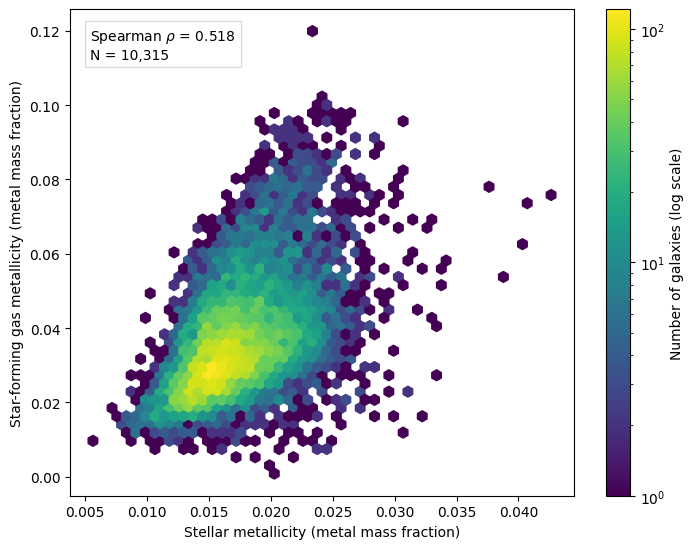

In [45]:
# ============================================================
# CELL 45
# Compare gas and stellar metallicities
# ============================================================

from scipy.stats import spearmanr
import matplotlib.pyplot as plt

Z_gas = eagle_science["SF_Metallicity"].to_numpy(float)
Z_stars = eagle_science["Stars_Metallicity"].to_numpy(float)
M_stars = eagle_science["Mstar_30pkpc"].to_numpy(float)

valid_gas = np.isfinite(Z_gas) & (Z_gas > 0)
valid_stars = np.isfinite(Z_stars) & (Z_stars > 0)
valid_both = valid_gas & valid_stars

rho_gas_stars = spearmanr(
    Z_gas[valid_both],
    Z_stars[valid_both]
).statistic

rho_mass_gas = spearmanr(
    np.log10(M_stars[valid_both]),
    Z_gas[valid_both]
).statistic

rho_mass_stars = spearmanr(
    np.log10(M_stars[valid_stars]),
    Z_stars[valid_stars]
).statistic

print("METALLICITY COMPARISON")
print("-" * 48)
print("Full science sample:", len(eagle_science))
print("Valid gas metallicity:", valid_gas.sum())
print("Valid stellar metallicity:", valid_stars.sum())
print("Valid in both:", valid_both.sum())

print(f"\nGas vs stellar metallicity rho: {rho_gas_stars:.3f}")
print(f"Mass vs gas metallicity rho:   {rho_mass_gas:.3f}")
print(f"Mass vs stellar metallicity rho: {rho_mass_stars:.3f}")

fig, ax = plt.subplots(figsize=(7.2, 5.6))

hb = ax.hexbin(
    Z_stars[valid_both],
    Z_gas[valid_both],
    gridsize=48,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

ax.set_xlabel("Stellar metallicity (metal mass fraction)")
ax.set_ylabel("Star-forming gas metallicity (metal mass fraction)")

ax.text(
    0.04, 0.96,
    f"Spearman $\\rho$ = {rho_gas_stars:.3f}\n"
    f"N = {valid_both.sum():,}",
    transform=ax.transAxes,utp
    va="top",
    fontsize=10,
    bbox=dict(
        facecolor="white",
        edgecolor="0.85",
        alpha=0.95
    )
)

fig.colorbar(
    hb,
    ax=ax,
    label="Number of galaxies (log scale)"
)

fig.tight_layout()

plt.show()

In [46]:
# ============================================================
# CELL 46
# Check EAGLE metallicity coverage of MOBSE grid
# ============================================================

MOBSE_Z_MIN = 0.0002
MOBSE_Z_MAX = 0.0200

records = []

for field in ["Stars_Metallicity", "SF_Metallicity"]:

    values = eagle_science[field].to_numpy(dtype=float)
    valid = np.isfinite(values) & (values > 0)
    z = values[valid]

    records.append({
        "Metallicity": field,
        "Valid galaxies": len(z),
        "Below MOBSE (%)": 100 * np.mean(z < MOBSE_Z_MIN),
        "Within MOBSE (%)": 100 * np.mean(
            (z >= MOBSE_Z_MIN) & (z <= MOBSE_Z_MAX)
        ),
        "Above MOBSE (%)": 100 * np.mean(z > MOBSE_Z_MAX),
        "Median Z": np.median(z),
        "P16 Z": np.percentile(z, 16),
        "P84 Z": np.percentile(z, 84)
    })

mobse_coverage = pd.DataFrame(records)

display(mobse_coverage.round(3))

,Metallicity,Valid galaxies,Below MOBSE (%),Within MOBSE (%),Above MOBSE (%),Median Z,P16 Z,P84 Z
0,Stars_Metallicity,13200,0.0,78.212,21.788,0.017,0.014,0.021
1,SF_Metallicity,10315,0.0,6.486,93.514,0.034,0.024,0.048


In [48]:
# ============================================================
# CELL 47
# MOBSE BBH merger efficiency versus metallicity
# Bounded log-log interpolation
# ============================================================

import numpy as np
import pandas as pd

# Giacobbo, Mapelli & Spera (2018)
# Values transcribed from Chapter 5, Table 1.
# Units: merging BBHs per unit initial stellar mass.

MOBSE_Z = np.array([
    0.0002, 0.0004, 0.0008, 0.0012,
    0.0016, 0.0020, 0.0040, 0.0060,
    0.0080, 0.0120, 0.0160, 0.0200
])

MOBSE_ETA = np.array([
    8.7e-5, 1.0e-4, 7.9e-5, 6.9e-5,
    6.1e-5, 5.0e-5, 5.5e-6, 9.2e-7,
    4.8e-7, 2.4e-7, 1.8e-7, 1.0e-7
])

# Validate the reference grid.
assert np.all(np.diff(MOBSE_Z) > 0)
assert np.all(MOBSE_ETA > 0)


def mobse_efficiency(metallicity):
    """
    Convert absolute metal mass fraction to a MOBSE
    BBH merger-efficiency weight.

    Uses log-log interpolation inside the tabulated
    metallicity range.

    Outside the range, the nearest boundary value
    is used. This is a modelling assumption, not
    a validated prediction beyond the MOBSE grid.
    """

    z = np.asarray(metallicity, dtype=float)

    if not np.all(np.isfinite(z)):
        raise ValueError("Non-finite metallicity detected.")

    if np.any(z <= 0):
        raise ValueError("Metallicity must be positive.")

    z_bounded = np.clip(
        z,
        MOBSE_Z.min(),
        MOBSE_Z.max()
    )

    log_eta = np.interp(
        np.log10(z_bounded),
        np.log10(MOBSE_Z),
        np.log10(MOBSE_ETA)
    )

    return 10 ** log_eta


# TEST 1: Exact recovery of tabulated efficiencies.
np.testing.assert_allclose(
    mobse_efficiency(MOBSE_Z),
    MOBSE_ETA,
    rtol=1e-12
)

# TEST 2: Upper-boundary treatment.
np.testing.assert_allclose(
    mobse_efficiency(np.array([0.03, 0.05])),
    np.array([MOBSE_ETA[-1], MOBSE_ETA[-1]]),
    rtol=1e-12
)

# TEST 3: Lower-boundary treatment.
np.testing.assert_allclose(
    mobse_efficiency(np.array([0.0001])),
    np.array([MOBSE_ETA[0]]),
    rtol=1e-12
)

print("PASS: MOBSE interpolation and boundary tests.")

display(pd.DataFrame({
    "Metallicity_Z": MOBSE_Z,
    "BBH_efficiency_per_Msun": MOBSE_ETA
}))

PASS: MOBSE interpolation and boundary tests.


,Metallicity_Z,BBH_efficiency_per_Msun
0,0.0002,8.700000e-05
1,0.0004,1.000000e-04
2,0.0008,7.900000e-05
3,0.0012,6.900000e-05
4,0.0016,6.100000e-05
5,0.0020,5.000000e-05
6,0.0040,5.500000e-06
7,0.0060,9.200000e-07
8,0.0080,4.800000e-07
9,0.0120,2.400000e-07


In [49]:
# ============================================================
# CELL 48
# Apply metallicity and mass-metallicity host priors
# to the reference EAGLE cube
# ============================================================

import numpy as np
import pandas as pd

# Work with the existing reference cube.
reference_probabilities = reference_cube.copy()

# Verify the expected sample.
assert len(reference_probabilities) == 402
assert reference_probabilities["GalaxyID"].is_unique

# Retrieve physical properties.
Z = reference_probabilities[
    "Stars_Metallicity"
].to_numpy(dtype=float)

Mstar = reference_probabilities[
    "Mstar_30pkpc"
].to_numpy(dtype=float)

SFR = reference_probabilities[
    "SFR_30pkpc"
].to_numpy(dtype=float)

# Validate metallicity and mass.
assert np.all(np.isfinite(Z) & (Z > 0))
assert np.all(np.isfinite(Mstar) & (Mstar > 0))
assert np.all(np.isfinite(SFR) & (SFR >= 0))

# Identify galaxies above the MOBSE calibration grid.
reference_probabilities["MOBSE_above_grid"] = (
    Z > MOBSE_Z.max()
)

# Calculate model efficiency per unit initial stellar mass.
reference_probabilities["MOBSE_eta"] = mobse_efficiency(Z)

# Two distinct astrophysical host-prior prescriptions.
weights_Z = reference_probabilities[
    "MOBSE_eta"
].to_numpy(dtype=float)

weights_MZ = Mstar * weights_Z

# Normalise over the same 402-galaxy sample.
reference_probabilities["P_Z"] = normalise_host_weights(
    weights_Z
)

reference_probabilities["P_MZ"] = normalise_host_weights(
    weights_MZ
)

# Recalculate the original three priors on the same sample.
reference_probabilities["P_flat"] = normalise_host_weights(
    np.ones(len(reference_probabilities))
)

reference_probabilities["P_mass"] = normalise_host_weights(
    Mstar
)

reference_probabilities["P_SFR"] = normalise_host_weights(
    SFR
)

# Validate all five models.
prior_columns = [
    "P_flat", "P_mass", "P_SFR", "P_Z", "P_MZ"
]

for column in prior_columns:
    np.testing.assert_allclose(
        reference_probabilities[column].sum(),
        1.0,
        atol=1e-12
    )

print("REFERENCE CUBE — FIVE PRIOR MODELS")
print("-" * 55)
print("Galaxies:", len(reference_probabilities))

print(
    "Above MOBSE upper boundary:",
    int(reference_probabilities["MOBSE_above_grid"].sum())
)

for column in prior_columns:
    print(
        f"{column}: "
        f"{reference_probabilities[column].sum():.12f}"
    )

print("\nPASS: All five priors normalised correctly.")

display(
    reference_probabilities[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "Stars_Metallicity",
            "MOBSE_eta",
            "P_mass",
            "P_Z",
            "P_MZ"
        ]
    ].head(10)
)

REFERENCE CUBE — FIVE PRIOR MODELS
-------------------------------------------------------
Galaxies: 402
Above MOBSE upper boundary: 80
P_flat: 1.000000000000
P_mass: 1.000000000000
P_SFR: 1.000000000000
P_Z: 1.000000000000
P_MZ: 1.000000000000

PASS: All five priors normalised correctly.


,GalaxyID,Mstar_30pkpc,Stars_Metallicity,MOBSE_eta,P_mass,P_Z,P_MZ
0,10552361,8.358051e+09,0.020001,1.000000e-07,0.001536,0.001524,0.001221
1,11627402,1.355766e+09,0.013283,2.168226e-07,0.000249,0.003304,0.000429
2,11869398,1.388122e+09,0.013207,2.180623e-07,0.000255,0.003323,0.000442
3,11937811,2.982138e+09,0.015149,1.901162e-07,0.000548,0.002897,0.000828
4,12617264,2.837739e+09,0.016991,1.536533e-07,0.000521,0.002341,0.000637
5,8868680,1.429959e+10,0.019189,1.115193e-07,0.002627,0.001699,0.002329
6,9972238,2.491106e+10,0.025111,1.000000e-07,0.004577,0.001524,0.003639
7,10301150,1.280408e+09,0.014047,2.050200e-07,0.000235,0.003124,0.000383
8,11923856,2.497424e+09,0.017492,1.423323e-07,0.000459,0.002169,0.000519
9,12786643,6.535288e+09,0.018832,1.171732e-07,0.001201,0.001785,0.001119


In [50]:
# ============================================================
# CELL 49
# Top-ten candidates under both metallicity priors
# ============================================================

for label, probability_column in [
    ("Metallicity-only", "P_Z"),
    ("Mass × metallicity", "P_MZ")
]:

    ranked = reference_probabilities.sort_values(
        [probability_column, "GalaxyID"],
        ascending=[False, True]
    )

    top10 = ranked.head(10)

    print("\n" + "=" * 60)
    print(label.upper())
    print("=" * 60)

    display(
        top10[
            [
                "GalaxyID",
                "Mstar_30pkpc",
                "Stars_Metallicity",
                "MOBSE_eta",
                probability_column
            ]
        ]
    )

    print(
        "Top-ten probability:",
        f"{top10[probability_column].sum():.4f}"
    )

    print(
        "Galaxies above MOBSE grid in top ten:",
        int(top10["MOBSE_above_grid"].sum())
    )


METALLICITY-ONLY


,GalaxyID,Mstar_30pkpc,Stars_Metallicity,MOBSE_eta,P_Z
253,6690381,1.049686e+09,0.008809,4.070836e-07,0.006203
169,3417414,1.411785e+09,0.009424,3.627762e-07,0.005528
204,4189656,1.104855e+09,0.009604,3.511948e-07,0.005351
247,6690869,1.288661e+09,0.010107,3.218478e-07,0.004904
196,5978048,1.047078e+09,0.010228,3.153680e-07,0.004805
289,8435853,1.182444e+10,0.010276,3.128786e-07,0.004768
155,3431641,1.199135e+09,0.010608,2.963172e-07,0.004515
179,3888616,1.023934e+09,0.010785,2.880387e-07,0.004389
331,14883340,5.983604e+10,0.010843,2.854276e-07,0.004349
305,5040473,1.953251e+09,0.010859,2.846870e-07,0.004338


Top-ten probability: 0.0492
Galaxies above MOBSE grid in top ten: 0

MASS × METALLICITY


,GalaxyID,Mstar_30pkpc,Stars_Metallicity,MOBSE_eta,P_MZ
311,18781589,2.572008e+11,0.018169,1.287688e-07,0.048379
391,19250447,2.320766e+11,0.017998,1.320294e-07,0.044758
323,19534448,1.612636e+11,0.018463,1.234537e-07,0.029081
270,19595681,1.936739e+11,0.021905,1.000000e-07,0.028291
331,14883340,5.983604e+10,0.010843,2.854276e-07,0.024948
394,19556663,1.625425e+11,0.020218,1.000000e-07,0.023743
362,19575152,1.426138e+11,0.019506,1.068035e-07,0.022249
361,17596949,9.570472e+10,0.016968,1.541962e-07,0.021556
280,19800923,1.315134e+11,0.020093,1.000000e-07,0.019211
356,15451066,5.860986e+10,0.014298,2.014241e-07,0.017245


Top-ten probability: 0.2795
Galaxies above MOBSE grid in top ten: 3


In [51]:
# ============================================================
# CELL 50
# MOBSE high-metallicity boundary sensitivity
# ============================================================

import numpy as np
import pandas as pd

# Start with the 402-galaxy reference sample.
boundary_sample = reference_probabilities.copy()

Z = boundary_sample["Stars_Metallicity"].to_numpy(float)
M = boundary_sample["Mstar_30pkpc"].to_numpy(float)

assert len(boundary_sample) == 402
assert np.all(np.isfinite(Z) & (Z > 0))
assert np.all(np.isfinite(M) & (M > 0))

# The existing bounded-interpolation model.
eta_clamped = mobse_efficiency(Z)

# Log-log extrapolation of the last two MOBSE points.
upper_log_slope = (
    np.log(MOBSE_ETA[-1] / MOBSE_ETA[-2])
    / np.log(MOBSE_Z[-1] / MOBSE_Z[-2])
)

def mobse_extrapolated(z):
    """
    Use MOBSE log-log interpolation inside the grid.
    Above the grid, extend the slope of its final
    two points.

    This extension is a sensitivity experiment,
    not a calibrated physical prediction.
    """
    z = np.asarray(z, dtype=float)

    if np.any(~np.isfinite(z)) or np.any(z <= 0):
        raise ValueError("Metallicity must be finite and positive.")

    eta = mobse_efficiency(z)

    above = z > MOBSE_Z[-1]

    eta[above] = (
        MOBSE_ETA[-1]
        * (z[above] / MOBSE_Z[-1]) ** upper_log_slope
    )

    return eta


eta_extrapolated = mobse_extrapolated(Z)

# Check that the two models agree within the grid.
inside = (Z >= MOBSE_Z[0]) & (Z <= MOBSE_Z[-1])

np.testing.assert_allclose(
    eta_clamped[inside],
    eta_extrapolated[inside],
    rtol=1e-12
)

# Calculate full-sample probabilities for both
# metallicity-only and mass-times-metallicity models.
boundary_sample["P_Z_clamped"] = normalise_host_weights(
    eta_clamped
)

boundary_sample["P_Z_extrapolated"] = normalise_host_weights(
    eta_extrapolated
)

boundary_sample["P_MZ_clamped"] = normalise_host_weights(
    M * eta_clamped
)

boundary_sample["P_MZ_extrapolated"] = normalise_host_weights(
    M * eta_extrapolated
)

# The restricted sample is a separate experiment.
restricted_sample = boundary_sample.loc[inside].copy()

Z_r = restricted_sample["Stars_Metallicity"].to_numpy(float)
M_r = restricted_sample["Mstar_30pkpc"].to_numpy(float)
SFR_r = restricted_sample["SFR_30pkpc"].to_numpy(float)

eta_r = mobse_efficiency(Z_r)

restricted_sample["P_flat"] = normalise_host_weights(
    np.ones(len(restricted_sample))
)

restricted_sample["P_mass"] = normalise_host_weights(M_r)
restricted_sample["P_SFR"] = normalise_host_weights(SFR_r)

restricted_sample["P_Z"] = normalise_host_weights(eta_r)
restricted_sample["P_MZ"] = normalise_host_weights(M_r * eta_r)

print("MOBSE BOUNDARY SENSITIVITY SETUP")
print("-" * 52)
print("Full sample:", len(boundary_sample))
print("Within calibration:", len(restricted_sample))
print("Above calibration:", int(np.sum(Z > MOBSE_Z[-1])))
print("Upper extrapolation slope:", round(upper_log_slope, 3))

print("\nPASS: Boundary models constructed.")

MOBSE BOUNDARY SENSITIVITY SETUP
----------------------------------------------------
Full sample: 402
Within calibration: 322
Above calibration: 80
Upper extrapolation slope: -2.634

PASS: Boundary models constructed.


In [52]:
# ============================================================
# CELL 51
# MOBSE boundary sensitivity metrics
# ============================================================

def concentration_metrics(probabilities):
    """
    Calculate probability concentration metrics
    for one normalised galaxy population.
    """
    p = np.asarray(probabilities, dtype=float)

    assert len(p) > 0
    assert np.all(np.isfinite(p))
    assert np.all(p >= 0)
    np.testing.assert_allclose(p.sum(), 1.0, atol=1e-12)

    ranked = np.sort(p)[::-1]
    cumulative = np.cumsum(ranked)

    return {
        "N_galaxies": len(p),
        "N50": int(np.searchsorted(cumulative, 0.50) + 1),
        "N90": int(np.searchsorted(cumulative, 0.90) + 1),
        "P1_pct": 100 * ranked[0],
        "C5_pct": 100 * ranked[:5].sum(),
        "C10_pct": 100 * ranked[:10].sum()
    }


models = [
    ("Z only", "Clamped", boundary_sample, "P_Z_clamped"),
    ("Z only", "Extrapolated", boundary_sample, "P_Z_extrapolated"),
    ("Z only", "Restricted", restricted_sample, "P_Z"),
    ("Mass × Z", "Clamped", boundary_sample, "P_MZ_clamped"),
    ("Mass × Z", "Extrapolated", boundary_sample, "P_MZ_extrapolated"),
    ("Mass × Z", "Restricted", restricted_sample, "P_MZ")
]

rows = []

for prior, treatment, sample, column in models:
    rows.append({
        "Prior": prior,
        "Boundary treatment": treatment,
        **concentration_metrics(sample[column])
    })

boundary_metrics = pd.DataFrame(rows)

print("PROBABILITY CONCENTRATION")
display(boundary_metrics.round(3))


# Compare probability distributions on the same
# 402-galaxy sample using total variation distance.
def total_variation(p, q):
    return 0.5 * np.abs(
        np.asarray(p) - np.asarray(q)
    ).sum()


# Compare the identities of the ten highest-ranked
# galaxies under the two full-sample assumptions.
def top10_ids(sample, probability_column):
    return set(
        sample.nlargest(10, probability_column)["GalaxyID"]
    )


comparisons = []

for prior, clamped, extrapolated in [
    ("Z only", "P_Z_clamped", "P_Z_extrapolated"),
    ("Mass × Z", "P_MZ_clamped", "P_MZ_extrapolated")
]:

    overlap = len(
        top10_ids(boundary_sample, clamped)
        & top10_ids(boundary_sample, extrapolated)
    )

    comparisons.append({
        "Prior": prior,
        "TV_distance": total_variation(
            boundary_sample[clamped],
            boundary_sample[extrapolated]
        ),
        "Top10_overlap": overlap
    })

boundary_comparison = pd.DataFrame(comparisons)

print("\nCLAMPED VS EXTRAPOLATED — SAME 402 GALAXIES")
display(boundary_comparison.round(4))


# A separate, matched-sample comparison:
# How much does retaining only in-grid galaxies
# change the weighting relative to a clamped
# model renormalised on those very same galaxies?
matched_rows = []

for prior, full_column, restricted_column in [
    ("Z only", "P_Z_clamped", "P_Z"),
    ("Mass × Z", "P_MZ_clamped", "P_MZ")
]:

    selected = boundary_sample.loc[
        inside, full_column
    ].to_numpy(float)

    selected = normalise_host_weights(selected)

    restricted = restricted_sample[
        restricted_column
    ].to_numpy(float)

    matched_rows.append({
        "Prior": prior,
        "TV_on_matched_sample": total_variation(
            selected, restricted
        )
    })

print("\nMATCHED IN-GRID GALAXIES — CONSISTENCY CHECK")
display(pd.DataFrame(matched_rows).round(8))

PROBABILITY CONCENTRATION


,Prior,Boundary treatment,N_galaxies,N50,N90,P1_pct,C5_pct,C10_pct
0,Z only,Clamped,402,150,337,0.620,2.679,4.915
1,Z only,Extrapolated,402,144,317,0.642,2.772,5.085
2,Z only,Restricted,322,129,272,0.706,3.051,5.597
3,Mass × Z,Clamped,402,32,203,4.838,17.546,27.946
4,Mass × Z,Extrapolated,402,31,213,5.354,18.839,30.159
5,Mass × Z,Restricted,322,18,181,7.808,27.343,40.189



CLAMPED VS EXTRAPOLATED — SAME 402 GALAXIES


,Prior,TV_distance,Top10_overlap
0,Z only,0.0305,10
1,Mass × Z,0.0709,10



MATCHED IN-GRID GALAXIES — CONSISTENCY CHECK


,Prior,TV_on_matched_sample
0,Z only,0.0
1,Mass × Z,0.0


In [53]:
# ============================================================
# CELL 52
# Diagnose SFR behaviour before implementing Artale Fit 3D
# ============================================================

import numpy as np
import pandas as pd

sfr = reference_cube["SFR_30pkpc"].to_numpy(dtype=float)
mass = reference_cube["Mstar_30pkpc"].to_numpy(dtype=float)
metal = reference_cube["Stars_Metallicity"].to_numpy(dtype=float)

assert np.all(np.isfinite(sfr) & (sfr >= 0))
assert np.all(np.isfinite(mass) & (mass > 0))
assert np.all(np.isfinite(metal) & (metal > 0))

positive_sfr = sfr[sfr > 0]

print("ARTALE JOINT PRIOR — INPUT DIAGNOSTICS")
print("-" * 55)
print("Total galaxies:", len(sfr))
print("Zero-SFR galaxies:", int(np.sum(sfr == 0)))
print("Positive-SFR galaxies:", len(positive_sfr))

print("\nPositive-SFR distribution (Msun/yr):")
print(f"Minimum: {positive_sfr.min():.8g}")

for percentile in [1, 5, 16, 50, 84, 95, 99]:
    print(
        f"P{percentile:02d}: "
        f"{np.percentile(positive_sfr, percentile):.8g}"
    )

print(f"Maximum: {positive_sfr.max():.8g}")

# Quantify how strongly the SFR component alone changes
# for representative low but strictly positive SFR values.
gamma_sfr = -0.051

test_sfr = np.array([
    1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0
])

sfr_factors = test_sfr ** gamma_sfr

display(pd.DataFrame({
    "SFR_Msun_per_year": test_sfr,
    "Artale_SFR_factor": sfr_factors
}))

print("\nPASS: Artale input diagnostic complete.")

ARTALE JOINT PRIOR — INPUT DIAGNOSTICS
-------------------------------------------------------
Total galaxies: 402
Zero-SFR galaxies: 73
Positive-SFR galaxies: 329

Positive-SFR distribution (Msun/yr):
Minimum: 0.003073039
P01: 0.0052695838
P05: 0.014273834
P16: 0.043311094
P50: 0.2075754
P84: 0.82665228
P95: 2.2961506
P99: 4.2890897
Maximum: 6.1149397


,SFR_Msun_per_year,Artale_SFR_factor
0,0.00001,1.798871
1,0.00010,1.599558
2,0.00100,1.422329
3,0.01000,1.264736
4,0.10000,1.124605
5,1.00000,1.000000
6,10.00000,0.889201



PASS: Artale input diagnostic complete.


In [56]:
# ============================================================
# CELL 53 — REPLACEMENT
# Artale joint prior on a clean positive-SFR sample
# ============================================================

import numpy as np
import pandas as pd

ARTALE_GAMMA_M = 0.921
ARTALE_GAMMA_SFR = -0.051
ARTALE_GAMMA_Z = -0.404

# Start from the physical galaxy properties, not from
# a DataFrame containing previously calculated priors.
physical_columns = [
    "GalaxyID",
    "Mstar_30pkpc",
    "SFR_30pkpc",
    "Stars_Metallicity",
    "SF_Metallicity"
]

artale_sample = reference_cube.loc[
    reference_cube["SFR_30pkpc"] > 0,
    physical_columns
].copy().reset_index(drop=True)

assert len(artale_sample) == 329
assert artale_sample.columns.is_unique
assert artale_sample["GalaxyID"].is_unique

M = artale_sample["Mstar_30pkpc"].to_numpy(float)
SFR = artale_sample["SFR_30pkpc"].to_numpy(float)
Z = artale_sample["Stars_Metallicity"].to_numpy(float)

assert np.all(np.isfinite(M) & (M > 0))
assert np.all(np.isfinite(SFR) & (SFR > 0))
assert np.all(np.isfinite(Z) & (Z > 0))


def artale_weights(mass, sfr, metallicity):
    """
    Relative weights based on Artale Fit 3D:

    H proportional to:
        Mstar^0.921 * SFR^-0.051 * Z^-0.404

    The common multiplicative constant cancels
    during probability normalisation.
    """

    m = np.asarray(mass, dtype=float)
    s = np.asarray(sfr, dtype=float)
    z = np.asarray(metallicity, dtype=float)

    if not (m.shape == s.shape == z.shape):
        raise ValueError("Artale inputs must have matching shapes.")

    if (
        np.any(~np.isfinite(m)) or
        np.any(~np.isfinite(s)) or
        np.any(~np.isfinite(z)) or
        np.any(m <= 0) or
        np.any(s <= 0) or
        np.any(z <= 0)
    ):
        raise ValueError("Artale inputs must be finite and positive.")

    log_w = (
        ARTALE_GAMMA_M * np.log(m)
        + ARTALE_GAMMA_SFR * np.log(s)
        + ARTALE_GAMMA_Z * np.log(z)
    )

    return np.exp(log_w - np.max(log_w))


# Calculate each prior independently.
eta = mobse_efficiency(Z)

artale_sample["P_flat"] = normalise_host_weights(
    np.ones(len(artale_sample))
)

artale_sample["P_mass"] = normalise_host_weights(M)

artale_sample["P_SFR"] = normalise_host_weights(SFR)

artale_sample["P_Z"] = normalise_host_weights(eta)

artale_sample["P_MZ"] = normalise_host_weights(M * eta)

artale_sample["P_Artale"] = normalise_host_weights(
    artale_weights(M, SFR, Z)
)

# Validate all six probability distributions.
prior_cols = [
    "P_flat",
    "P_mass",
    "P_SFR",
    "P_Z",
    "P_MZ",
    "P_Artale"
]

print("ARTALE MATCHED-SAMPLE VALIDATION")
print("-" * 55)
print("Galaxies:", len(artale_sample))
print("Unique columns:", artale_sample.columns.is_unique)

for col in prior_cols:
    total = artale_sample[col].sum()

    np.testing.assert_allclose(
        total, 1.0, atol=1e-12
    )

    print(f"{col}: {total:.12f}")

np.testing.assert_allclose(
    artale_sample["P_flat"].to_numpy(),
    np.full(329, 1 / 329)
)

print("\nPASS: All six priors correctly normalised.")

display(
    artale_sample[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "Stars_Metallicity",
            "P_flat",
            "P_mass",
            "P_MZ",
            "P_Artale"
        ]
    ].head(10)
)

ARTALE MATCHED-SAMPLE VALIDATION
-------------------------------------------------------
Galaxies: 329
Unique columns: True
P_flat: 1.000000000000
P_mass: 1.000000000000
P_SFR: 1.000000000000
P_Z: 1.000000000000
P_MZ: 1.000000000000
P_Artale: 1.000000000000

PASS: All six priors correctly normalised.


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,Stars_Metallicity,P_flat,P_mass,P_MZ,P_Artale
0,10552361,8.358051e+09,0.167142,0.020001,0.00304,0.001738,0.001383,0.002031
1,11627402,1.355766e+09,0.147639,0.013283,0.00304,0.000282,0.000486,0.000452
2,11869398,1.388122e+09,0.049733,0.013207,0.00304,0.000289,0.000501,0.000489
3,11937811,2.982138e+09,0.407484,0.015149,0.00304,0.000620,0.000938,0.000841
4,12617264,2.837739e+09,0.175095,0.016991,0.00304,0.000590,0.000721,0.000800
5,8868680,1.429959e+10,0.287255,0.019189,0.00304,0.002974,0.002638,0.003295
6,9972238,2.491106e+10,1.101589,0.025111,0.00304,0.005180,0.004121,0.004601
7,10301150,1.280408e+09,0.093537,0.014047,0.00304,0.000266,0.000434,0.000429
8,11923856,2.497424e+09,0.154148,0.017492,0.00304,0.000519,0.000588,0.000708
9,12786643,6.535288e+09,0.183691,0.018832,0.00304,0.001359,0.001267,0.001651


In [57]:
# ============================================================
# CELL 54
# Compare Artale against five priors
# on the SAME positive-SFR population
# ============================================================

comparison_priors = {
    "Flat": "P_flat",
    "Stellar mass": "P_mass",
    "SFR": "P_SFR",
    "Metallicity": "P_Z",
    "Mass × metallicity": "P_MZ",
    "Artale joint": "P_Artale"
}

rows = []

for name, col in comparison_priors.items():
    rows.append({
        "Prior": name,
        **concentration_metrics(artale_sample[col])
    })

artale_concentration = pd.DataFrame(rows)

print("POSITIVE-SFR SAMPLE — PROBABILITY CONCENTRATION")
display(artale_concentration.round(3))

print("\nTOP TEN — ARTALE JOINT PRIOR")

display(
    artale_sample.nlargest(
        10, "P_Artale"
    )[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "Stars_Metallicity",
            "P_Artale"
        ]
    ]
)

# Compare identities of top-ten candidates.
artale_top10 = set(
    artale_sample.nlargest(10, "P_Artale")["GalaxyID"]
)

overlap_rows = []

for name, col in comparison_priors.items():
    if name == "Flat":
        continue

    comparison_top10 = set(
        artale_sample.nlargest(10, col)["GalaxyID"]
    )

    overlap_rows.append({
        "Comparison": f"Artale vs {name}",
        "Top10_overlap": len(
            artale_top10 & comparison_top10
        )
    })

print("\nARTALE TOP-TEN OVERLAP")
display(pd.DataFrame(overlap_rows))

POSITIVE-SFR SAMPLE — PROBABILITY CONCENTRATION


,Prior,N_galaxies,N50,N90,P1_pct,C5_pct,C10_pct
0,Flat,329,165,297,0.304,1.520,3.040
1,Stellar mass,329,22,128,5.349,20.936,32.981
2,SFR,329,31,151,3.616,14.143,24.404
3,Metallicity,329,125,276,0.676,3.002,5.531
4,Mass × metallicity,329,24,160,5.479,19.871,31.650
5,Artale joint,329,29,163,4.570,17.426,28.220



TOP TEN — ARTALE JOINT PRIOR


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,Stars_Metallicity,P_Artale
320,19250447,2.320766e+11,0.138327,0.017998,0.045703
260,18781589,2.572008e+11,4.627411,0.018169,0.041846
229,19595681,1.936739e+11,2.724785,0.021905,0.030698
269,19534448,1.612636e+11,1.935585,0.018463,0.028277
297,19575152,1.426138e+11,0.198250,0.019506,0.027739
323,19556663,1.625425e+11,4.455964,0.020218,0.026314
236,19800923,1.315134e+11,3.244844,0.020093,0.022058
296,17596949,9.570472e+10,0.051039,0.016968,0.021780
246,15172288,8.899104e+10,0.010035,0.021683,0.020044
317,17193503,1.131447e+11,3.746344,0.023997,0.017744



ARTALE TOP-TEN OVERLAP


,Comparison,Top10_overlap
0,Artale vs Stellar mass,9
1,Artale vs SFR,3
2,Artale vs Metallicity,0
3,Artale vs Mass × metallicity,8
4,Artale vs Artale joint,10


In [58]:
# ============================================================
# CELL 55
# Artale full-sample sensitivity to zero-SFR treatment
# ============================================================

ARTALE_SFR_FLOORS = [1e-4, 1e-3, 1e-2]

artale_full = reference_cube.copy()

M = artale_full["Mstar_30pkpc"].to_numpy(float)
SFR = artale_full["SFR_30pkpc"].to_numpy(float)
Z = artale_full["Stars_Metallicity"].to_numpy(float)

assert len(artale_full) == 402
assert artale_full["GalaxyID"].is_unique
assert np.all(np.isfinite(SFR) & (SFR >= 0))

zero_sfr = SFR == 0

# Recalculate full-population comparison priors.
artale_full["P_flat"] = normalise_host_weights(
    np.ones(len(artale_full))
)
artale_full["P_mass"] = normalise_host_weights(M)
artale_full["P_SFR"] = normalise_host_weights(SFR)

eta = mobse_efficiency(Z)

artale_full["P_Z"] = normalise_host_weights(eta)
artale_full["P_MZ"] = normalise_host_weights(M * eta)

floor_rows = []

for floor in ARTALE_SFR_FLOORS:

    sfr_modified = SFR.copy()
    sfr_modified[zero_sfr] = floor

    column = f"P_Artale_floor_{floor:g}"

    artale_full[column] = normalise_host_weights(
        artale_weights(M, sfr_modified, Z)
    )

    p = artale_full[column].to_numpy(float)

    floor_rows.append({
        "SFR_floor": floor,
        **concentration_metrics(p),
        "Zero_SFR_weight_pct": 100 * p[zero_sfr].sum(),
        "Top10_overlap_with_mass": len(
            set(artale_full.nlargest(10, column)["GalaxyID"])
            & set(artale_full.nlargest(10, "P_mass")["GalaxyID"])
        )
    })

artale_floor_metrics = pd.DataFrame(floor_rows)

print("ARTALE FULL-SAMPLE SFR-FLOOR SENSITIVITY")
print("-" * 60)
print("Total galaxies:", len(artale_full))
print("Zero-SFR galaxies:", int(zero_sfr.sum()))

display(artale_floor_metrics.round(4))

ARTALE FULL-SAMPLE SFR-FLOOR SENSITIVITY
------------------------------------------------------------
Total galaxies: 402
Zero-SFR galaxies: 73


,SFR_floor,N_galaxies,N50,N90,P1_pct,C5_pct,C10_pct,Zero_SFR_weight_pct,Top10_overlap_with_mass
0,0.0001,402,39,207,3.7761,14.3979,23.3161,17.3778,9
1,0.0010,402,39,206,3.8502,14.6806,23.7739,15.7558,9
2,0.0100,402,38,206,3.9187,14.9414,24.1963,14.2590,9


In [59]:
# ============================================================
# CELL 56
# Compare full-sample Artale probability distributions
# ============================================================

comparisons = []

for i, floor_a in enumerate(ARTALE_SFR_FLOORS):
    for floor_b in ARTALE_SFR_FLOORS[i + 1:]:

        col_a = f"P_Artale_floor_{floor_a:g}"
        col_b = f"P_Artale_floor_{floor_b:g}"

        p = artale_full[col_a].to_numpy(float)
        q = artale_full[col_b].to_numpy(float)

        top_a = set(
            artale_full.nlargest(10, col_a)["GalaxyID"]
        )
        top_b = set(
            artale_full.nlargest(10, col_b)["GalaxyID"]
        )

        comparisons.append({
            "SFR_floor_A": floor_a,
            "SFR_floor_B": floor_b,
            "TV_distance": total_variation(p, q),
            "Top10_overlap": len(top_a & top_b),
            "N50_A": concentration_metrics(p)["N50"],
            "N50_B": concentration_metrics(q)["N50"]
        })

artale_floor_comparison = pd.DataFrame(comparisons)

print("ARTALE SFR-FLOOR COMPARISONS")
display(artale_floor_comparison.round(5))

# Additional check: changing the floor must not alter
# the relative Artale weights of two positive-SFR galaxies.
positive_indices = np.flatnonzero(SFR > 0)

i, j = positive_indices[:2]

for floor in ARTALE_SFR_FLOORS:
    col = f"P_Artale_floor_{floor:g}"
    print(
        f"Floor {floor:g}: positive-SFR weight ratio = "
        f"{artale_full[col].iloc[i] / artale_full[col].iloc[j]:.8f}"
    )

ARTALE SFR-FLOOR COMPARISONS


,SFR_floor_A,SFR_floor_B,TV_distance,Top10_overlap,N50_A,N50_B
0,0.0001,0.001,0.01622,10,39,39
1,0.0001,0.010,0.03119,10,39,38
2,0.0010,0.010,0.01497,10,39,38


Floor 0.0001: positive-SFR weight ratio = 4.49733695
Floor 0.001: positive-SFR weight ratio = 4.49733695
Floor 0.01: positive-SFR weight ratio = 4.49733695


In [60]:

# ============================================================
# CELL 57
# Reconstruct the 500 mock volumes with metallicity data
# ============================================================

import numpy as np
import pandas as pd

assert len(ensemble) == N_CUBES == 500
assert len(eagle_science) == 13200
assert eagle_science["GalaxyID"].is_unique

required_columns = [
    "GalaxyID", "x", "y", "z",
    "Mstar_30pkpc", "SFR_30pkpc",
    "Stars_Metallicity", "SF_Metallicity"
]

assert all(c in eagle_science.columns for c in required_columns)

# Use cube_id as the permanent identifier, not row position.
assert ensemble["cube_id"].is_unique

cube_catalogues = {}
validation_rows = []

for record in ensemble.itertuples(index=False):

    cube_id = int(record.cube_id)

    origin = np.array([
        record.origin_x,
        record.origin_y,
        record.origin_z
    ], dtype=float)

    cube = sample_periodic_cube(
        eagle_science,
        origin,
        L,
        box_size=100.0
    ).copy()

    assert cube["GalaxyID"].is_unique
    assert len(cube) > 0

    # Every galaxy must meet our adopted science threshold.
    assert (cube["Mstar_30pkpc"] >= MASS_MIN).all()

    # Check essential physical quantities.
    assert np.isfinite(
        cube[["Mstar_30pkpc", "SFR_30pkpc",
              "Stars_Metallicity"]].to_numpy(float)
    ).all()

    assert (cube["Mstar_30pkpc"] > 0).all()
    assert (cube["SFR_30pkpc"] >= 0).all()
    assert (cube["Stars_Metallicity"] > 0).all()

    cube_catalogues[cube_id] = cube

    validation_rows.append({
        "cube_id": cube_id,
        "N_reconstructed": len(cube),
        "N_original": int(record.N_galaxies)
    })

cube_validation = pd.DataFrame(validation_rows)

cube_validation["N_difference"] = (
    cube_validation["N_reconstructed"]
    - cube_validation["N_original"]
)

assert (cube_validation["N_difference"] == 0).all()

print("ENSEMBLE RECONSTRUCTION")
print("-" * 55)
print("Mock volumes:", len(cube_catalogues))
print("Total galaxy appearances:",
      cube_validation["N_reconstructed"].sum())
print("Count mismatches:",
      (cube_validation["N_difference"] != 0).sum())

print("\nPASS: All 500 cube memberships reproduced.")


ENSEMBLE RECONSTRUCTION
-------------------------------------------------------
Mock volumes: 500
Total galaxy appearances: 215889
Count mismatches: 0

PASS: All 500 cube memberships reproduced.


In [61]:

# ============================================================
# CELL 58
# Calculate six prior models in every mock volume
# ============================================================

ARTALE_BASELINE_FLOOR = 1e-3

ensemble_probabilities = {}
prior_validation_rows = []

prior_names = {
    "Flat": "P_flat",
    "Stellar mass": "P_mass",
    "SFR": "P_SFR",
    "Metallicity": "P_Z",
    "Mass × metallicity": "P_MZ",
    "Artale joint": "P_Artale"
}


def calculate_six_priors(cube, sfr_floor=1e-3):
    """Return a galaxy catalogue with six normalised priors."""

    # Start clean: never inherit probabilities from an
    # earlier calculation with a different sample.
    result = cube.drop(
        columns=list(prior_names.values()),
        errors="ignore"
    ).copy()

    assert result.columns.is_unique
    assert result["GalaxyID"].is_unique
    assert len(result) > 0

    mass = result["Mstar_30pkpc"].to_numpy(float)
    sfr = result["SFR_30pkpc"].to_numpy(float)
    metallicity = result["Stars_Metallicity"].to_numpy(float)

    if not np.isfinite(sfr_floor) or sfr_floor <= 0:
        raise ValueError("Artale SFR floor must be positive.")

    if not np.all(np.isfinite(mass) & (mass > 0)):
        raise ValueError("Invalid stellar masses.")

    if not np.all(np.isfinite(sfr) & (sfr >= 0)):
        raise ValueError("Invalid SFR values.")

    if not np.all(np.isfinite(metallicity) & (metallicity > 0)):
        raise ValueError("Invalid stellar metallicities.")

    eta = mobse_efficiency(metallicity)

    # Only exact zero SFRs receive the Artale floor.
    sfr_artale = sfr.copy()
    sfr_artale[sfr_artale == 0] = sfr_floor

    weights = {
        "P_flat": np.ones(len(result)),
        "P_mass": mass,
        "P_SFR": sfr,
        "P_Z": eta,
        "P_MZ": mass * eta,
        "P_Artale": artale_weights(
            mass, sfr_artale, metallicity
        )
    }

    for column, raw_weights in weights.items():
        result[column] = normalise_host_weights(raw_weights)

    result["MOBSE_above_grid"] = (
        metallicity > MOBSE_Z[-1]
    )

    return result


for cube_id, cube in cube_catalogues.items():

    result = calculate_six_priors(
        cube,
        sfr_floor=ARTALE_BASELINE_FLOOR
    )

    ensemble_probabilities[cube_id] = result

    sums = result[list(prior_names.values())].sum()

    np.testing.assert_allclose(
        sums.to_numpy(float),
        np.ones(len(prior_names)),
        rtol=1e-12,
        atol=1e-12
    )

    sfr_zero = result["SFR_30pkpc"] == 0

    assert (result.loc[sfr_zero, "P_SFR"] == 0).all()

    prior_validation_rows.append({
        "cube_id": cube_id,
        "N_galaxies": len(result),
        "N_zero_SFR": int(sfr_zero.sum()),
        "N_above_MOBSE": int(
            result["MOBSE_above_grid"].sum()
        ),
        "max_normalisation_error": float(
            np.max(np.abs(sums.to_numpy(float) - 1.0))
        )
    })

prior_validation = pd.DataFrame(prior_validation_rows)

print("SIX-PRIOR ENSEMBLE VALIDATION")
print("-" * 55)
print("Mock volumes:", len(ensemble_probabilities))
print("Prior distributions:", 6 * len(ensemble_probabilities))
print("Largest normalisation error:",
      f"{prior_validation['max_normalisation_error'].max():.3e}")

print("\nPASS: All 3,000 prior distributions normalised.")


SIX-PRIOR ENSEMBLE VALIDATION
-------------------------------------------------------
Mock volumes: 500
Prior distributions: 3000
Largest normalisation error: 6.661e-16

PASS: All 3,000 prior distributions normalised.


In [62]:

# ============================================================
# CELL 59
# Probability concentration across 500 mock volumes
# ============================================================

concentration_rows = []

for cube_id, cube in ensemble_probabilities.items():

    for prior_label, probability_column in prior_names.items():

        metrics = concentration_metrics(
            cube[probability_column].to_numpy(float)
        )

        concentration_rows.append({
            "cube_id": cube_id,
            "Prior": prior_label,
            **metrics
        })

ensemble_concentration = pd.DataFrame(concentration_rows)

assert len(ensemble_concentration) == 500 * 6

assert not ensemble_concentration.duplicated(
    ["cube_id", "Prior"]
).any()

assert (
    ensemble_concentration["N50"]
    <= ensemble_concentration["N90"]
).all()

assert (
    ensemble_concentration["N90"]
    <= ensemble_concentration["N_galaxies"]
).all()

assert (
    ensemble_concentration["P1_pct"]
    <= ensemble_concentration["C5_pct"]
).all()

assert (
    ensemble_concentration["C5_pct"]
    <= ensemble_concentration["C10_pct"]
).all()

print("ENSEMBLE PROBABILITY CONCENTRATION")
print("-" * 55)
print("Rows:", len(ensemble_concentration))
print("Cubes:", ensemble_concentration["cube_id"].nunique())
print("Priors:", ensemble_concentration["Prior"].nunique())

display(ensemble_concentration.head(12))

print("\nPASS: Concentration metrics calculated.")


ENSEMBLE PROBABILITY CONCENTRATION
-------------------------------------------------------
Rows: 3000
Cubes: 500
Priors: 6


,cube_id,Prior,N_galaxies,N50,N90,P1_pct,C5_pct,C10_pct
0,0,Flat,440,221,396,0.227273,1.136364,2.272727
1,0,Stellar mass,440,40,205,5.574305,14.659385,23.094248
2,0,SFR,440,44,188,3.377519,12.684035,21.362722
3,0,Metallicity,440,163,370,0.600637,2.486747,4.584763
4,0,Mass × metallicity,440,46,247,5.259147,15.787676,23.070513
5,0,Artale joint,440,48,241,4.214627,12.737788,20.273960
6,1,Flat,647,324,583,0.154560,0.772798,1.545595
7,1,Stellar mass,647,50,277,2.793339,11.451910,19.394928
8,1,SFR,647,50,242,2.793656,9.648510,17.059360
9,1,Metallicity,647,241,544,1.148834,2.670296,4.159989



PASS: Concentration metrics calculated.


In [64]:
# ============================================================
# CELL 60A
# Fix cumulative-probability floating-point precision
# and regenerate ensemble concentration results
# ============================================================

import numpy as np
import pandas as pd

def concentration_metrics(probabilities):
    p = np.asarray(probabilities, dtype=float)

    if p.ndim != 1 or len(p) == 0:
        raise ValueError("Expected a non-empty 1D array.")

    if not np.all(np.isfinite(p)) or np.any(p < 0):
        raise ValueError("Invalid probabilities.")

    np.testing.assert_allclose(
        p.sum(), 1.0, rtol=1e-12, atol=1e-12
    )

    ranked = np.sort(p)[::-1]
    cumulative = np.cumsum(ranked)

    tolerance = 1e-12

    return {
        "N_galaxies": len(p),
        "N50": int(
            np.searchsorted(cumulative, 0.50 - tolerance) + 1
        ),
        "N90": int(
            np.searchsorted(cumulative, 0.90 - tolerance) + 1
        ),
        "P1_pct": 100 * ranked[0],
        "C5_pct": 100 * ranked[:5].sum(),
        "C10_pct": 100 * ranked[:10].sum()
    }


# Test against the exact flat-prior solution.
for n in range(1, 1501):
    p = np.full(n, 1.0 / n)
    metrics = concentration_metrics(p)

    assert metrics["N50"] == int(np.ceil(0.5 * n))
    assert metrics["N90"] == int(np.ceil(0.9 * n))

print("PASS: Numerical precision tests.")


# Recalculate all 3,000 cube/prior combinations.
concentration_rows = []

for cube_id, cube in ensemble_probabilities.items():
    for prior_label, probability_column in prior_names.items():

        concentration_rows.append({
            "cube_id": cube_id,
            "Prior": prior_label,
            **concentration_metrics(
                cube[probability_column].to_numpy(float)
            )
        })

ensemble_concentration = pd.DataFrame(concentration_rows)

assert len(ensemble_concentration) == 3000


# Rebuild the summary table.
metric_columns = [
    "N50", "N90", "P1_pct", "C5_pct", "C10_pct"
]

summary_rows = []
thesis_rows = []

for prior_label in prior_names:

    subset = ensemble_concentration[
        ensemble_concentration["Prior"] == prior_label
    ]

    summary = {
        "Prior": prior_label,
        "N_cubes": len(subset)
    }

    display_row = {"Prior": prior_label}

    for metric in metric_columns:
        values = subset[metric].to_numpy(float)

        median = np.median(values)
        p16 = np.percentile(values, 16)
        p84 = np.percentile(values, 84)

        summary[f"{metric}_median"] = median
        summary[f"{metric}_p16"] = p16
        summary[f"{metric}_p84"] = p84

        if metric in ["N50", "N90"]:
            display_row[metric] = (
                f"{median:.1f} [{p16:.1f}, {p84:.1f}]"
            )
        else:
            display_row[metric] = (
                f"{median:.2f}% [{p16:.2f}, {p84:.2f}]"
            )

    summary_rows.append(summary)
    thesis_rows.append(display_row)

concentration_summary = pd.DataFrame(summary_rows)
thesis_concentration_table = pd.DataFrame(thesis_rows)


# Verify flat-prior results against analytic expectations.
flat_rows = ensemble_concentration[
    ensemble_concentration["Prior"] == "Flat"
]

n = flat_rows["N_galaxies"].to_numpy(int)

assert np.array_equal(
    flat_rows["N50"].to_numpy(int),
    np.ceil(0.5 * n).astype(int)
)

assert np.array_equal(
    flat_rows["N90"].to_numpy(int),
    np.ceil(0.9 * n).astype(int)
)

print("\nPASS: All 3,000 distributions recalculated.")
print("PASS: Flat-prior analytic validation.")

print("\nCORRECTED SECTION 6.5 RESULTS")
display(thesis_concentration_table)

PASS: Numerical precision tests.

PASS: All 3,000 distributions recalculated.
PASS: Flat-prior analytic validation.

CORRECTED SECTION 6.5 RESULTS


,Prior,N50,N90,P1_pct,C5_pct,C10_pct
0,Flat,"190.5 [107.8, 311.3]","342.5 [194.7, 560.6]","0.26% [0.16, 0.46]","1.31% [0.80, 2.32]","2.63% [1.61, 4.64]"
1,Stellar mass,"32.0 [19.0, 47.0]","172.5 [102.0, 262.0]","4.78% [3.56, 6.71]","16.60% [12.94, 22.60]","26.28% [20.88, 35.53]"
2,SFR,"35.0 [22.0, 51.0]","155.5 [98.8, 224.0]","4.12% [2.83, 6.52]","14.22% [10.65, 21.48]","23.56% [18.15, 33.21]"
3,Metallicity,"145.0 [83.0, 228.2]","322.5 [180.7, 522.5]","0.72% [0.52, 1.18]","2.84% [2.12, 4.41]","5.09% [3.79, 7.95]"
4,Mass × metallicity,"34.0 [22.0, 51.0]","211.5 [123.8, 330.2]","5.18% [3.73, 7.22]","17.27% [13.81, 22.08]","26.70% [21.32, 33.36]"
5,Artale joint,"41.0 [24.8, 61.0]","214.0 [124.5, 329.3]","3.84% [2.84, 5.66]","13.77% [10.71, 19.74]","22.57% [17.42, 30.96]"


In [65]:

# ============================================================
# CELL 60
# Summarise concentration across the 500 mock volumes
# ============================================================

metric_columns = [
    "N50", "N90", "P1_pct", "C5_pct", "C10_pct"
]

summary_rows = []

for prior_label in prior_names:

    subset = ensemble_concentration.loc[
        ensemble_concentration["Prior"] == prior_label
    ]

    row = {
        "Prior": prior_label,
        "N_cubes": len(subset)
    }

    for metric in metric_columns:

        values = subset[metric].to_numpy(float)

        row[f"{metric}_median"] = np.median(values)
        row[f"{metric}_p16"] = np.percentile(values, 16)
        row[f"{metric}_p84"] = np.percentile(values, 84)

    summary_rows.append(row)

concentration_summary = pd.DataFrame(summary_rows)

assert (concentration_summary["N_cubes"] == 500).all()

# Compact, readable version for inspecting results.
thesis_rows = []

for _, record in concentration_summary.iterrows():

    row = {"Prior": record["Prior"]}

    for metric in metric_columns:

        median = record[f"{metric}_median"]
        p16 = record[f"{metric}_p16"]
        p84 = record[f"{metric}_p84"]

        if metric in ["N50", "N90"]:
            row[metric] = (
                f"{median:.1f} [{p16:.1f}, {p84:.1f}]"
            )
        else:
            row[metric] = (
                f"{median:.2f}% [{p16:.2f}, {p84:.2f}]"
            )

    thesis_rows.append(row)

thesis_concentration_table = pd.DataFrame(thesis_rows)

print("SECTION 6.5 — PROBABILITY CONCENTRATION")
print("Median [16th, 84th percentile] across 500 cubes")
print("-" * 70)

display(thesis_concentration_table)

# Independently verify the analytic flat-prior result.
flat_rows = ensemble_concentration.loc[
    ensemble_concentration["Prior"] == "Flat"
].copy()

n = flat_rows["N_galaxies"].to_numpy(int)

np.testing.assert_allclose(
    flat_rows["P1_pct"].to_numpy(float),
    100 / n,
    rtol=1e-12,
    atol=1e-12
)

np.testing.assert_allclose(
    flat_rows["C10_pct"].to_numpy(float),
    100 * np.minimum(10, n) / n,
    rtol=1e-12,
    atol=1e-12
)

assert np.array_equal(
    flat_rows["N50"].to_numpy(int),
    np.ceil(0.5 * n).astype(int)
)

# A small tolerance avoids floating-point
# ambiguity at exact cumulative thresholds.
assert np.all(
    np.abs(
        flat_rows["N90"].to_numpy(int)
        - np.ceil(0.9 * n).astype(int)
    ) <= 1
)

print("\nPASS: Flat-prior analytic checks.")


SECTION 6.5 — PROBABILITY CONCENTRATION
Median [16th, 84th percentile] across 500 cubes
----------------------------------------------------------------------


,Prior,N50,N90,P1_pct,C5_pct,C10_pct
0,Flat,"190.5 [107.8, 311.3]","342.5 [194.7, 560.6]","0.26% [0.16, 0.46]","1.31% [0.80, 2.32]","2.63% [1.61, 4.64]"
1,Stellar mass,"32.0 [19.0, 47.0]","172.5 [102.0, 262.0]","4.78% [3.56, 6.71]","16.60% [12.94, 22.60]","26.28% [20.88, 35.53]"
2,SFR,"35.0 [22.0, 51.0]","155.5 [98.8, 224.0]","4.12% [2.83, 6.52]","14.22% [10.65, 21.48]","23.56% [18.15, 33.21]"
3,Metallicity,"145.0 [83.0, 228.2]","322.5 [180.7, 522.5]","0.72% [0.52, 1.18]","2.84% [2.12, 4.41]","5.09% [3.79, 7.95]"
4,Mass × metallicity,"34.0 [22.0, 51.0]","211.5 [123.8, 330.2]","5.18% [3.73, 7.22]","17.27% [13.81, 22.08]","26.70% [21.32, 33.36]"
5,Artale joint,"41.0 [24.8, 61.0]","214.0 [124.5, 329.3]","3.84% [2.84, 5.66]","13.77% [10.71, 19.74]","22.57% [17.42, 30.96]"



PASS: Flat-prior analytic checks.


In [66]:
# ============================================================
# CELL 61
# Save the corrected 500-cube Bayesian analysis
# ============================================================

from pathlib import Path
import json
import pandas as pd

DATA.mkdir(parents=True, exist_ok=True)

# 1. Save all 3,000 cube/prior concentration measurements
ensemble_concentration.to_csv(
    DATA / "EAGLE_500cube_prior_concentration.csv",
    index=False
)

# 2. Save numerical summary statistics
concentration_summary.to_csv(
    DATA / "EAGLE_500cube_concentration_summary.csv",
    index=False
)

# 3. Save the readable results table
thesis_concentration_table.to_csv(
    DATA / "EAGLE_500cube_thesis_results.csv",
    index=False
)

# 4. Save validation results
prior_validation.to_csv(
    DATA / "EAGLE_500cube_prior_validation.csv",
    index=False
)

# 5. Preserve individual galaxy probabilities
probability_catalogue = pd.concat(
    [
        cube.assign(cube_id=cube_id)
        for cube_id, cube in ensemble_probabilities.items()
    ],
    ignore_index=True
)

probability_catalogue.to_csv(
    DATA / "EAGLE_500cube_galaxy_probabilities.csv",
    index=False
)

# 6. Record the modelling assumptions
model_config = {
    "simulation": "RefL0100N1504",
    "snapshot": 28,
    "parent_mass_floor_Msun": 1e8,
    "science_mass_floor_Msun": float(MASS_MIN),
    "mock_volume_cMpc3": float(V90),
    "mock_side_length_cMpc": float(L),
    "number_of_cubes": int(N_CUBES),
    "ensemble_seed": int(ENSEMBLE_SEED),
    "stellar_mass_aperture_pkpc": 30,
    "metallicity_field": "Stars_Metallicity",
    "mobse_interpolation": "Log-log linear",
    "mobse_boundary": "Clamped to grid endpoints",
    "artale_mass_exponent": 0.921,
    "artale_sfr_exponent": -0.051,
    "artale_metallicity_exponent": -0.404,
    "artale_zero_sfr_floor": 1e-3,
    "note": (
        "Mock cubes may overlap. Percentiles describe "
        "variation within one finite EAGLE simulation, "
        "not independent cosmological realisations."
    )
}

with open(
    DATA / "EAGLE_500cube_model_configuration.json",
    "w"
) as f:
    json.dump(model_config, f, indent=2)

# 7. Final verification
assert len(ensemble_concentration) == 3000
assert len(concentration_summary) == 6
assert len(ensemble_probabilities) == 500

print("PASS: Bayesian ensemble results saved.")
print()
print("Files saved in:", DATA.resolve())
print("Cube/prior measurements:", len(ensemble_concentration))
print("Individual galaxy appearances:", len(probability_catalogue))
print("Prior models:", len(concentration_summary))

PASS: Bayesian ensemble results saved.

Files saved in: /content/data
Cube/prior measurements: 3000
Individual galaxy appearances: 215889
Prior models: 6


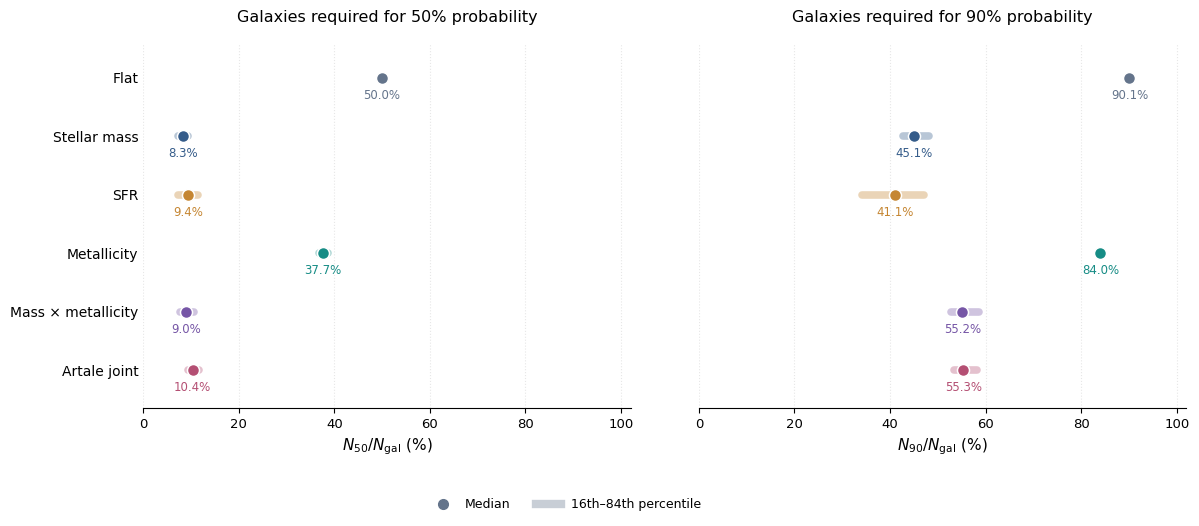

FRACTIONAL PROBABILITY CONCENTRATION


,Prior,f50_pct_median,f50_pct_p16,f50_pct_p84,f90_pct_median,f90_pct_p16,f90_pct_p84
0,Flat,50.00,50.00,50.17,90.10,90.02,90.24
1,Stellar mass,8.27,7.31,9.46,45.08,42.64,48.12
2,SFR,9.35,7.33,11.39,41.06,34.14,47.12
3,Metallicity,37.67,36.72,38.62,84.01,83.74,84.31
4,Mass × metallicity,9.00,7.76,10.61,55.15,52.79,58.59
5,Artale joint,10.39,9.49,11.71,55.34,53.45,58.15



PASS: Figure and summary generated.


In [67]:

# ============================================================
# CELL 62
# Figure: Fractional probability concentration
# across 500 EAGLE mock volumes
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Work with the validated 3,000-row concentration dataset.
plot_data = ensemble_concentration.copy()

assert len(plot_data) == 3000
assert plot_data["cube_id"].nunique() == 500

# Compute fractional concentration PER CUBE.
plot_data["f50_pct"] = (
    100 * plot_data["N50"] / plot_data["N_galaxies"]
)

plot_data["f90_pct"] = (
    100 * plot_data["N90"] / plot_data["N_galaxies"]
)

# Preserve a scientifically meaningful prior order.
prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Artale joint"
]

# Colours chosen to distinguish the six models.
prior_colors = {
    "Flat": "#64748B",
    "Stellar mass": "#355C8A",
    "SFR": "#C58632",
    "Metallicity": "#168C85",
    "Mass × metallicity": "#7656A6",
    "Artale joint": "#B44F73"
}

# Summarise medians and percentile ranges.
summary_rows = []

for prior in prior_order:

    subset = plot_data.loc[plot_data["Prior"] == prior]

    assert len(subset) == 500

    row = {"Prior": prior}

    for metric in ["f50_pct", "f90_pct"]:

        values = subset[metric].to_numpy(float)

        row[f"{metric}_median"] = np.median(values)
        row[f"{metric}_p16"] = np.percentile(values, 16)
        row[f"{metric}_p84"] = np.percentile(values, 84)

    summary_rows.append(row)

fractional_summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.8, 5.3),
    sharey=True
)

y_positions = np.arange(len(prior_order))

panel_settings = [
    ("f50_pct", r"$N_{50}/N_{\rm gal}$ (%)",
     "Galaxies required for 50% probability"),
    ("f90_pct", r"$N_{90}/N_{\rm gal}$ (%)",
     "Galaxies required for 90% probability")
]

for ax, (metric, xlabel, panel_title) in zip(
    axes, panel_settings
):

    for i, prior in enumerate(prior_order):

        record = fractional_summary.loc[
            fractional_summary["Prior"] == prior
        ].iloc[0]

        median = record[f"{metric}_median"]
        p16 = record[f"{metric}_p16"]
        p84 = record[f"{metric}_p84"]

        color = prior_colors[prior]

        # 16th–84th percentile interval.
        ax.plot(
            [p16, p84],
            [i, i],
            color=color,
            linewidth=5.5,
            alpha=0.35,
            solid_capstyle="round",
            zorder=2
        )

        # Median marker.
        ax.scatter(
            median,
            i,
            s=75,
            color=color,
            edgecolor="white",
            linewidth=1.1,
            zorder=3
        )

        # Direct numeric median label.
        ax.annotate(
            f"{median:.1f}%",
            (median, i),
            xytext=(0, -15),
            textcoords="offset points",
            ha="center",
            fontsize=8.5,
            color=color
        )

    ax.set_title(
        panel_title,
        fontsize=11.5,
        pad=15
    )

    ax.set_xlabel(xlabel, fontsize=11)

    ax.set_xlim(0, 102)
    ax.set_xticks(np.arange(0, 101, 20))

    ax.grid(
        axis="x",
        linestyle=":",
        linewidth=0.8,
        alpha=0.3
    )

    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=9.5)

for ax in axes:
    ax.set_yticks(y_positions)
    ax.set_yticklabels(prior_order, fontsize=10)
    ax.invert_yaxis()
    ax.set_ylim(len(prior_order) - 0.35, -0.6)

# Small, restrained figure legend.
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="#64748B",
        markersize=7,
        linewidth=0,
        label="Median"
    ),
    Line2D(
        [0], [0],
        color="#64748B",
        linewidth=6,
        alpha=0.35,
        label="16th–84th percentile"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.025),
    ncol=2,
    frameon=False,
    fontsize=9
)

fig.subplots_adjust(
    left=0.17,
    right=0.985,
    top=0.88,
    bottom=0.19,
    wspace=0.14
)

# Save high-resolution figure.
fig.savefig(
    DATA / "EAGLE_500cube_fractional_concentration.pdf",
    bbox_inches="tight"
)

fig.savefig(
    DATA / "EAGLE_500cube_fractional_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("FRACTIONAL PROBABILITY CONCENTRATION")
display(fractional_summary.round(2))

print("\nPASS: Figure and summary generated.")


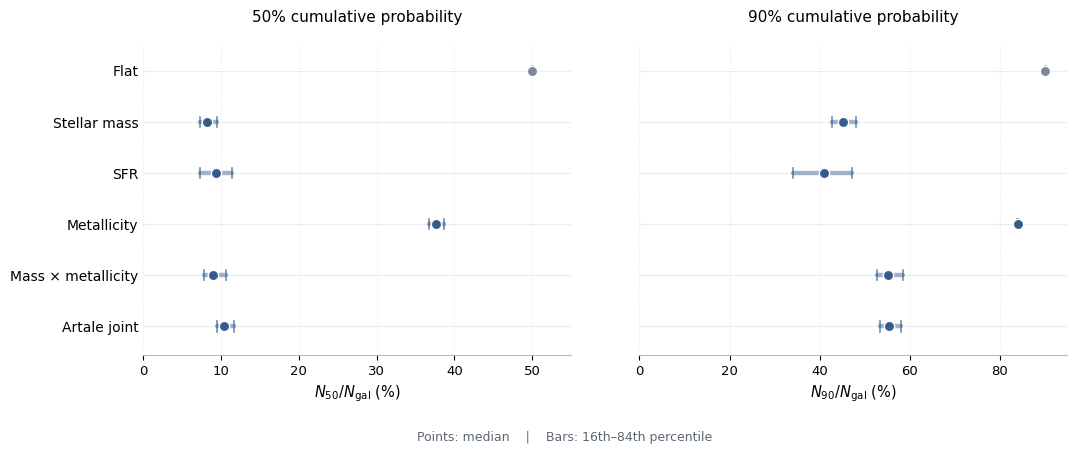

PASS: Revised fractional-concentration figure saved.


In [68]:

# ============================================================
# CELL 63
# Publication-style fractional probability concentration
# Cleaner two-panel design
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the validated results from Cell 62.
plot_data = ensemble_concentration.copy()

plot_data["f50_pct"] = (
    100 * plot_data["N50"] / plot_data["N_galaxies"]
)
plot_data["f90_pct"] = (
    100 * plot_data["N90"] / plot_data["N_galaxies"]
)

prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Artale joint"
]

summary_rows = []

for prior in prior_order:
    subset = plot_data[plot_data["Prior"] == prior]

    row = {"Prior": prior}

    for metric in ["f50_pct", "f90_pct"]:
        values = subset[metric].to_numpy(float)

        row[f"{metric}_median"] = np.median(values)
        row[f"{metric}_p16"] = np.percentile(values, 16)
        row[f"{metric}_p84"] = np.percentile(values, 84)

    summary_rows.append(row)

fractional_summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Figure design
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.7, 4.8),
    sharey=True
)

y = np.arange(len(prior_order))

# Flat control is grey; all astrophysical models are blue.
flat_color = "#7D8996"
model_color = "#355C8A"

panels = [
    ("f50_pct", 0, 55, 10,
     r"$N_{50}/N_{\rm gal}$ (%)",
     "50% cumulative probability"),
    ("f90_pct", 0, 95, 20,
     r"$N_{90}/N_{\rm gal}$ (%)",
     "90% cumulative probability")
]

for ax, (metric, xmin, xmax, tick_step, xlabel, heading) in zip(
    axes, panels
):

    # Light horizontal guides to help compare models.
    for yi in y:
        ax.axhline(
            yi,
            color="#E9EDF1",
            linewidth=0.8,
            zorder=0
        )

    for i, prior in enumerate(prior_order):

        record = fractional_summary[
            fractional_summary["Prior"] == prior
        ].iloc[0]

        median = record[f"{metric}_median"]
        low = record[f"{metric}_p16"]
        high = record[f"{metric}_p84"]

        color = (
            flat_color if prior == "Flat"
            else model_color
        )

        # Percentile range, with visible endpoints.
        ax.plot(
            [low, high],
            [i, i],
            color=color,
            linewidth=3.2,
            alpha=0.45,
            solid_capstyle="round",
            zorder=2
        )

        ax.plot(
            [low, low], [i-0.10, i+0.10],
            color=color, linewidth=1.2,
            alpha=0.7, zorder=2
        )
        ax.plot(
            [high, high], [i-0.10, i+0.10],
            color=color, linewidth=1.2,
            alpha=0.7, zorder=2
        )

        # Median point.
        ax.scatter(
            median, i,
            s=55,
            facecolor=color,
            edgecolor="white",
            linewidth=1,
            zorder=4
        )

    ax.set_xlim(xmin, xmax)
    ax.set_xticks(np.arange(xmin, xmax + 1, tick_step))
    ax.set_xlabel(xlabel, fontsize=10.5)
    ax.set_title(heading, fontsize=11, pad=15)

    ax.grid(
        axis="x",
        color="#E7EBF0",
        linestyle=":",
        linewidth=0.8
    )

    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=9.5)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#B5BDC6")

    ax.set_yticks(y)
    ax.set_yticklabels(prior_order, fontsize=10)

    ax.set_ylim(5.55, -0.55)

# Explanatory notation below the panels.
fig.text(
    0.55, 0.04,
    "Points: median    |    Bars: 16th–84th percentile",
    ha="center",
    fontsize=9,
    color="#5D6773"
)

fig.subplots_adjust(
    left=0.19,
    right=0.98,
    top=0.87,
    bottom=0.22,
    wspace=0.16
)

fig.savefig(
    DATA / "EAGLE_500cube_fractional_concentration_clean.pdf",
    bbox_inches="tight"
)

fig.savefig(
    DATA / "EAGLE_500cube_fractional_concentration_clean.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Revised fractional-concentration figure saved.")
